# Phát hiện và phân đoạn vết nứt mặt đường trên bộ CFD bằng xử lý ảnh cổ điển

**Bài toán.** Đầu vào là **ảnh gốc** RGB chụp mặt đường (CFD, 480×320). Đầu ra là **mặt nạ nhị phân** cùng kích thước, trong đó 1 = pixel vết nứt.

**Ràng buộc.** Chỉ dùng kiến thức của học phần; **không dùng học sâu hay mô hình huấn luyện sẵn**.

**Khó khăn cốt lõi.**
1. Vết nứt **mảnh** (1–5 px) và chỉ chiếm khoảng 1.6% số pixel, nên dữ liệu **lệch lớp** nặng.
2. Mặt đường có **kết cấu hạt** (sỏi, nhựa đường) dễ bị nhầm thành vết nứt.
3. Ảnh bị **chiếu sáng không đều**: có bóng đổ và vệt sáng.

## Bảng pipeline

Tham số khởi đầu **chỉ được chỉnh trên tập tune (30 ảnh)**, theo dãy thử ở cột cuối. Kết quả được báo cáo **một lần** trên **tập test (88 ảnh)**.

| Bước | Việc làm | Chương | Tham số khởi đầu | Dãy thử trên tập tune |
|---|---|---|---|---|
| 1. Dữ liệu | CFD 118 ảnh + nhãn pixel, chia ngẫu nhiên có cố định seed, nhãn về nhị phân | 9 | 30 tune / 88 test | – |
| 2.1 Chuyển ảnh xám | Y = 0.299R + 0.587G + 0.114B | 4 | – | – |
| 2.2 Khử nhiễu | Lọc trung vị | 3 | 3×3 | 3, 5 |
| 2.3 Bù chiếu sáng | B = trung vị cửa sổ lớn; R = 128·I/B; cắt về [0, 255] | 3 | 51×51 | 31, 51, 71 |
| 3.1 Làm trơn lược đồ của R | Trung bình trượt cửa sổ W | 5 | W = 3 | 1, 3, 5 |
| 3.2 Vùng tối hơn nền (D) | Ngưỡng tam giác θ trên lược đồ đã làm trơn; D = (R < θ) | 5 | θ tự động | – |
| 3.3 Vùng gần biên mạnh (E) | Sobel trên R, \|∇R\| = \|Gx\| + \|Gy\|, Otsu, rồi giãn | 5, 7 | giãn ellipse 5×5 | 3, 5, 7 |
| 3.4 Mặt nạ thô | M = D ∩ E | – | – | – |
| 4.1 Phép đóng | Nối đoạn nứt đứt | 7 | ellipse 5×5 | 3, 5, 7 |
| 4.2 Lọc diện tích | Bỏ thành phần liên thông nhỏ | 7 | < 30 px | 15, 30, 60 |
| 4.3 Lọc độ dãn | Trục dài / trục ngắn (hộp chữ nhật xoay); bỏ vùng tròn | 7 | < 3 | 2, 3, 4 |
| 5. Đánh giá | Dice, IoU, Precision, Recall trên tập test; so với Otsu và Canny | 5 | – | – |

```
ảnh RGB ─► 2.1 xám ─► 2.2 trung vị ─► 2.3 R = 128·I/B ─┬─► 3.1 làm trơn lược đồ ─► 3.2 tam giác ─► D ─┐
                                                        └─► 3.3 Sobel L1 ─► Otsu ─► giãn ─────────► E ─┤
                                                                                       3.4 M = D ∩ E ◄─┘
     ─► 4.1 đóng ─► 4.2 lọc diện tích ─► 4.3 lọc độ dãn ─► mặt nạ cuối ─► 5. Dice / IoU / P / R
```

In [1]:
import os, json, time, zipfile, itertools
import numpy as np
import cv2
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats

set_matplotlib_formats("jpeg")                                  # hình JPEG cho notebook nhẹ
plt.rcParams.update({"figure.dpi": 90, "axes.titlesize": 9})
pd.set_option("display.precision", 3)

ROOT = os.path.abspath("..")                                    # thư mục DoAn/ (notebook nằm trong code/)
SRC = os.path.normpath(os.path.join(ROOT, "..", "pavement crack datasets", "CFD"))
DATA = os.path.join(ROOT, "data", "cfd")
RES = os.path.join(ROOT, "results")
os.makedirs(RES, exist_ok=True)

SEED = 42
# Tham số khởi đầu (cột "Tham số khởi đầu" của bảng pipeline)
P0 = dict(median=3, bg=51, hist_w=3, dil=5, close=5, a_min=30, e_min=3)
# Dãy thử trên tập tune (cột cuối của bảng pipeline)
TUNE_SPACE = dict(median=[3, 5], bg=[31, 51, 71], hist_w=[1, 3, 5], dil=[3, 5, 7],
                  close=[3, 5, 7], a_min=[15, 30, 60], e_min=[2, 3, 4])
print("OpenCV", cv2.__version__, "| NumPy", np.__version__)

OpenCV 5.0.0 | NumPy 2.4.6


In [2]:
# ---- Hàm tiện ích hiển thị ----
def rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB) if img.ndim == 3 else img

def u8(mask):
    return mask.astype(np.uint8) * 255

def show_before_after(before, after, tb, ta, title, vmin_a=None, vmax_a=None):
    """In 5 ảnh TRƯỚC (hàng trên) và SAU (hàng dưới) một bước biến đổi."""
    n = len(before)
    fig, ax = plt.subplots(2, n, figsize=(3.3 * n, 5))
    for j in range(n):
        ax[0, j].imshow(rgb(before[j]), cmap="gray" if before[j].ndim == 2 else None)
        ax[0, j].set_title("TRƯỚC: " + tb[j])
        ax[1, j].imshow(rgb(after[j]), cmap="gray" if after[j].ndim == 2 else None, vmin=vmin_a, vmax=vmax_a)
        ax[1, j].set_title("SAU: " + ta[j])
        for a in ax[:, j]:
            a.axis("off")
    fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    plt.show()

def shp(img):
    return f"{img.shape[1]}×{img.shape[0]}" + ("×3" if img.ndim == 3 else "")

def overlay_red(img, mask, alpha=0.6):
    out = img.copy()
    out[mask] = (alpha * np.array([0, 0, 255]) + (1 - alpha) * img[mask]).astype(np.uint8)
    return out

def error_map(pred, gt):
    """Xanh lá = TP, đỏ = FP (báo nhầm), xanh dương = FN (bỏ sót)."""
    m = np.zeros(gt.shape + (3,), np.uint8)
    m[pred & gt] = (0, 200, 0); m[pred & ~gt] = (0, 0, 255); m[~pred & gt] = (255, 0, 0)
    return m

ncc = lambda m: cv2.connectedComponents(m.astype(np.uint8), connectivity=8)[0] - 1   # số vùng liên thông

---
# Bước 1 – Dữ liệu

### Nguồn
**CFD (CrackForest Dataset)**, Shi và cộng sự, 2016: ảnh mặt đường đô thị ở Bắc Kinh, chụp bằng điện thoại. Ảnh RGB, kích thước 480×320. Lấy từ `pavement crack datasets/CFD/cfd_image.zip` và `cfd_gt.zip`. Ảnh được giữ **nguyên byte gốc**, không nén lại.
* File zip ảnh có 155 ảnh, nhưng **chỉ 118 ảnh (`001`–`118`) có nhãn**. Các ảnh `201`–`329` không có GT nên bị loại.

### Cách gán nhãn và đưa nhãn về nhị phân
Mỗi ảnh có một mặt nạ PNG do người gán nhãn **vẽ tay ở mức pixel**. Nét vẽ **mảnh** (1–3 px), đi theo đường tâm của vết nứt.
* **Nhãn về nhị phân:** GT = (giá trị > 127). Như vậy 1 = vết nứt, 0 = nền. Bước này loại các giá trị trung gian có thể sinh ra khi lưu hoặc nén file.

### Chia tập
* **Cách chia:** **ngẫu nhiên** với **seed cố định = 42** (`numpy.random.default_rng(42).permutation`), nên ai chạy lại cũng được đúng cách chia này. Danh sách lưu ở `results/split.json`.
* **tune = 30 ảnh:** chỉ dùng để chọn tham số.
* **test = 88 ảnh:** chỉ dùng **một lần** để báo cáo kết quả. 88 ≥ 50 nên đạt yêu cầu của đề.
* **Lý do chia ngẫu nhiên** (thay vì lấy 30 ảnh đầu): số thứ tự ảnh trong CFD gần với thứ tự chụp, nên các ảnh liền nhau thường cùng một đoạn đường và cùng điều kiện chiếu sáng. Chia ngẫu nhiên giúp tập tune và tập test **đại diện như nhau**.

In [3]:
def prepare_cfd():
    zi = zipfile.ZipFile(os.path.join(SRC, "cfd_image.zip"))
    zg = zipfile.ZipFile(os.path.join(SRC, "cfd_gt.zip"))
    gts = {os.path.splitext(os.path.basename(n))[0]: n for n in zg.namelist()
           if n.lower().endswith(".png") and "__MACOSX" not in n}
    os.makedirs(os.path.join(DATA, "images"), exist_ok=True)
    os.makedirs(os.path.join(DATA, "masks"), exist_ok=True)
    for n in zi.namelist():
        sid = os.path.splitext(os.path.basename(n))[0]
        if n.lower().endswith(".jpg") and "__MACOSX" not in n and sid in gts:     # bỏ ảnh không có GT
            raw = zi.read(n)
            img = cv2.imdecode(np.frombuffer(raw, np.uint8), cv2.IMREAD_COLOR)
            gt = cv2.imdecode(np.frombuffer(zg.read(gts[sid]), np.uint8), cv2.IMREAD_GRAYSCALE)
            assert img.shape[:2] == gt.shape
            open(os.path.join(DATA, "images", sid + ".jpg"), "wb").write(raw)          # giữ nguyên byte ảnh gốc
            cv2.imwrite(os.path.join(DATA, "masks", sid + ".png"), np.where(gt > 127, 255, 0).astype(np.uint8))

if not os.path.isdir(os.path.join(DATA, "masks")) or len(os.listdir(os.path.join(DATA, "masks"))) != 118:
    prepare_cfd()

ALL_IDS = sorted(os.path.splitext(f)[0] for f in os.listdir(os.path.join(DATA, "masks")))
perm = np.random.default_rng(SEED).permutation(len(ALL_IDS))
TUNE_IDS = sorted(ALL_IDS[i] for i in perm[:30])
TEST_IDS = sorted(ALL_IDS[i] for i in perm[30:])
assert len(TUNE_IDS) == 30 and len(TEST_IDS) == 88 and not set(TUNE_IDS) & set(TEST_IDS)
json.dump({"seed": SEED, "tune": TUNE_IDS, "test": TEST_IDS}, open(os.path.join(RES, "split.json"), "w"), indent=1)
print("tune:", " ".join(TUNE_IDS))

def read_pair(sid):
    img = cv2.imread(os.path.join(DATA, "images", sid + ".jpg"))
    gt = cv2.imread(os.path.join(DATA, "masks", sid + ".png"), cv2.IMREAD_GRAYSCALE) > 127   # nhãn về nhị phân
    return img, gt

tune: 001 003 004 019 021 025 026 028 029 034 039 046 047 052 053 056 057 069 070 073 077 079 085 087 091 092 104 112 115 118


In [4]:
rows = []
for name, ids in (("tune", TUNE_IDS), ("test", TEST_IDS)):
    frac = [read_pair(i)[1].mean() * 100 for i in ids]
    rows.append({"tập": name, "số ảnh": len(ids), "kích thước": "480×320",
                 "% pixel nứt TB": np.mean(frac), "min": np.min(frac), "max": np.max(frac)})
pd.DataFrame(rows)

,tập,số ảnh,kích thước,% pixel nứt TB,min,max
0,tune,30,480×320,1.398,0.641,2.585
1,test,88,480×320,1.690,0.352,6.331


Trung bình chỉ khoảng **1.6% số pixel là vết nứt**. Một bộ phân đoạn "đoán toàn nền" vẫn đạt accuracy khoảng 98%, vì vậy ta dùng **Dice và IoU** thay cho accuracy.

Năm ảnh mẫu dưới đây được lấy ngẫu nhiên từ **tập tune** và dùng để minh họa từng bước. Mọi bước có **thay đổi không gian ảnh** (hệ màu, miền cường độ, chuyển sang ảnh nhị phân, hình thái) đều in 5 ảnh trước và sau biến đổi. Phần minh họa dùng **tham số khởi đầu**; tham số cuối cùng được chọn ở phần *Chọn tham số*.

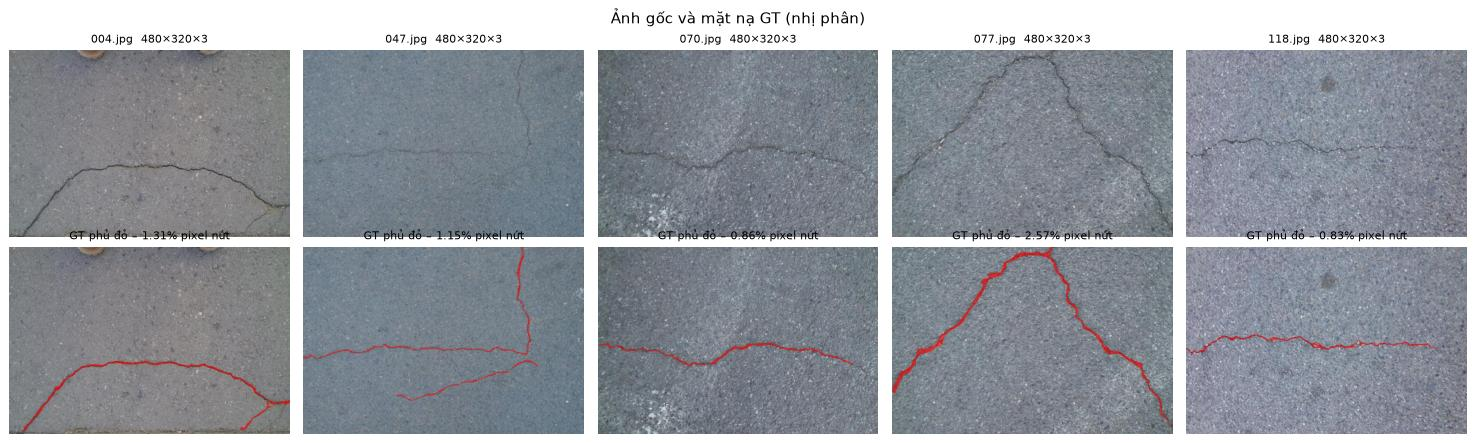

In [5]:
SAMPLE_IDS = sorted(np.random.default_rng(SEED).choice(TUNE_IDS, 5, replace=False))
S_IMG, S_GT = zip(*[read_pair(i) for i in SAMPLE_IDS])
fig, ax = plt.subplots(2, 5, figsize=(16.5, 5))
for j in range(5):
    ax[0, j].imshow(rgb(S_IMG[j])); ax[0, j].set_title(f"{SAMPLE_IDS[j]}.jpg  {shp(S_IMG[j])}")
    ax[1, j].imshow(rgb(overlay_red(S_IMG[j], S_GT[j]))); ax[1, j].set_title(f"GT phủ đỏ – {S_GT[j].mean()*100:.2f}% pixel nứt")
    for a in ax[:, j]: a.axis("off")
fig.suptitle("Ảnh gốc và mặt nạ GT (nhị phân)", fontsize=12); plt.tight_layout(); plt.show()

---
# Bước 2 – Tiền xử lý (Chương 3, 4)

## 2.1 Chuyển ảnh xám (Chương 4: hệ màu)

| | |
|---|---|
| **Dùng gì** | Chuyển BGR sang ảnh xám theo độ chói: **Y = 0.299R + 0.587G + 0.114B** (`cv2.COLOR_BGR2GRAY`). Ảnh đổi từ 3 kênh màu (480×320×3) sang 1 kênh cường độ (480×320) |
| **Tham số** | Không có. Các hệ số cố định theo chuẩn ITU-R BT.601 |
| **Tại sao** | Vết nứt khác nền ở **độ sáng** (khe hở ít nhận ánh sáng nên tối hơn), **không khác về màu**. Mặt đường và vết nứt cùng tông xám. Kênh H (sắc độ) của HSV gần như vô nghĩa với ảnh ít màu. Các trọng số Y mô phỏng độ nhạy của mắt người, trong đó kênh G có trọng số lớn nhất và cũng ít nhiễu nhất |

Ví dụ: pixel (R, G, B) = (120, 110, 100) cho Y = 35.88 + 64.57 + 11.40 = 111.85, làm tròn thành **112**.

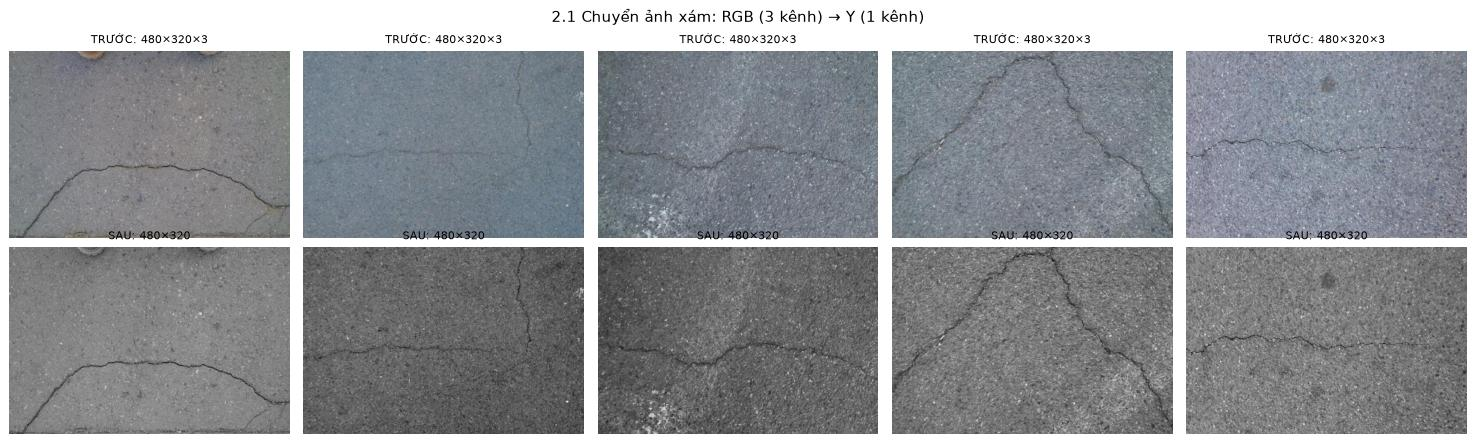

In [6]:
def to_gray(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

S_GRAY = [to_gray(x) for x in S_IMG]
show_before_after(S_IMG, S_GRAY, [shp(x) for x in S_IMG], [shp(x) for x in S_GRAY],
                  "2.1 Chuyển ảnh xám: RGB (3 kênh) → Y (1 kênh)")

## 2.2 Khử nhiễu bằng lọc trung vị (Chương 3)

| | |
|---|---|
| **Dùng gì** | Lọc trung vị cửa sổ k×k (`cv2.medianBlur`): mỗi pixel được thay bằng trung vị của k² pixel lân cận |
| **Tham số** | Khởi đầu **3×3**; thử **3, 5** trên tập tune |
| **Tại sao chọn trung vị** | Nhiễu trên mặt đường chủ yếu là các **hạt sỏi** nhỏ, sáng hoặc tối xen kẽ, có tính chất giống **nhiễu muối tiêu**. Theo Ch3, lọc trung vị là bộ lọc phù hợp nhất cho loại nhiễu này. Lọc trung bình và Gauss làm **nhòe** vết nứt mảnh |
| **Tại sao chỉ thử 3 và 5** | Với 3×3, một nét tối rộng **≥ 2 px** được giữ nguyên (6/9 pixel trong cửa sổ là tối, nên trung vị vẫn tối), còn đốm nhiễu cô lập bị xóa. 5×5 khử nhiễu mạnh hơn nhưng xóa luôn nét rộng 2 px (chỉ 10/25 pixel tối). Từ 7×7 trở lên thì xóa phần lớn vết nứt nên không thử |

```
Đốm nhiễu 1 px:                Vết nứt rộng 2 px:
120 120 120      120 120 120   120  60  60 120      120  60  60 120
120  30 120  ──► 120 120 120   120  60  60 120  ──► 120  60  60 120   (giữ nguyên với 3×3)
120 120 120      120 120 120   120  60  60 120      120  60  60 120
(bị xóa)
```

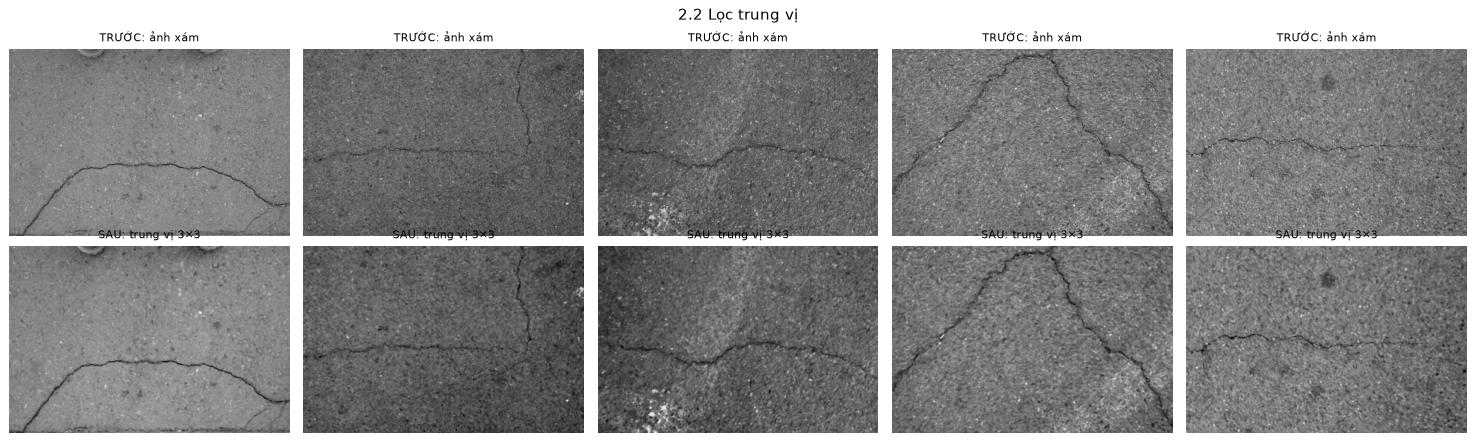

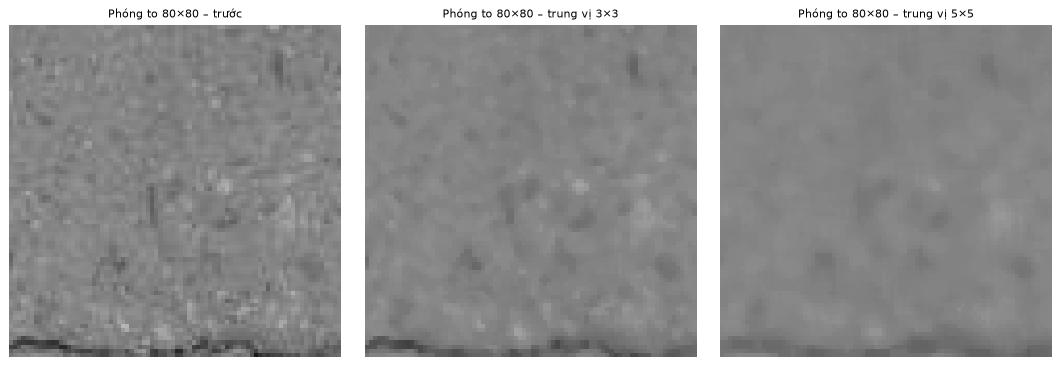

In [7]:
S_MED = [cv2.medianBlur(g, P0["median"]) for g in S_GRAY]
show_before_after(S_GRAY, S_MED, ["ảnh xám"] * 5, [f"trung vị {P0['median']}×{P0['median']}"] * 5, "2.2 Lọc trung vị")
y, x = 120, 180
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for a, (t, im) in zip(ax, [("trước", S_GRAY[0]), ("trung vị 3×3", S_MED[0]), ("trung vị 5×5", cv2.medianBlur(S_GRAY[0], 5))]):
    a.imshow(im[y:y+80, x:x+80], cmap="gray", vmin=0, vmax=255); a.set_title(f"Phóng to 80×80 – {t}"); a.axis("off")
plt.tight_layout(); plt.show()

## 2.3 Bù chiếu sáng: ảnh tỉ số R = 128·I/B (Chương 3)

| | |
|---|---|
| **Dùng gì** | (1) Ước lượng **ảnh nền** B = lọc trung vị với cửa sổ **lớn** bg×bg. (2) Tính **ảnh tỉ số** R = 128·I/(B + 1), rồi cắt về [0, 255]. Ảnh được chuyển từ miền cường độ **tuyệt đối** sang miền cường độ **tương đối so với nền**: nền ≈ 128, vết nứt < 128 |
| **Tham số** | Khởi đầu **51×51**; thử **31, 51, 71** trên tập tune |
| **Tại sao** | Vết nứt rất mảnh so với cửa sổ (vài px so với 51 px) nên chiếm rất ít pixel trong cửa sổ. Trung vị của cửa sổ vì vậy chính là **mức xám nền cục bộ**, và vết nứt bị "xóa" khỏi B. Bóng đổ và độ sáng thay đổi **chậm** nên nằm trong B; chia I cho B sẽ **triệt tiêu** chúng. Dùng **phép chia** thay vì phép trừ vì ánh sáng tác động theo kiểu **nhân**: vết nứt trong bóng râm và ngoài nắng có cùng tỉ lệ tối so với nền |
| **Phạm vi thử** | Cửa sổ phải **lớn hơn nhiều so với bề rộng vết nứt**, nếu không vết nứt lọt vào B rồi bị "chia mất". Đồng thời cửa sổ phải **nhỏ hơn kích thước vệt bóng** để theo kịp thay đổi chiếu sáng. Vì vậy thử 31 (nhạy với bóng nhỏ), 51 và 71 (ổn định với vết nứt rộng) |

```
vị trí    :   0    1    2    3    4    5    6    7    8    9   10
              ── nắng ──────────►  chuyển dần  ──── bóng râm ────
I (xám)   : 160  160  [96] 160  150  130  110  100  [60] 100  100
B (nền)   : 160  160  160  160  150  130  110  100  100  100  100
R=128·I/B : 127  127  [76] 127  127  127  126  126  [76] 126  126
→ Tách ngưỡng trên I (vd I < 105) sẽ gán nhầm vùng bóng râm (7, 9, 10) là vết nứt.
→ Trên R: nền luôn ≈ 127, cả hai vết nứt đều = 76, nên một ngưỡng duy nhất là đủ.
```

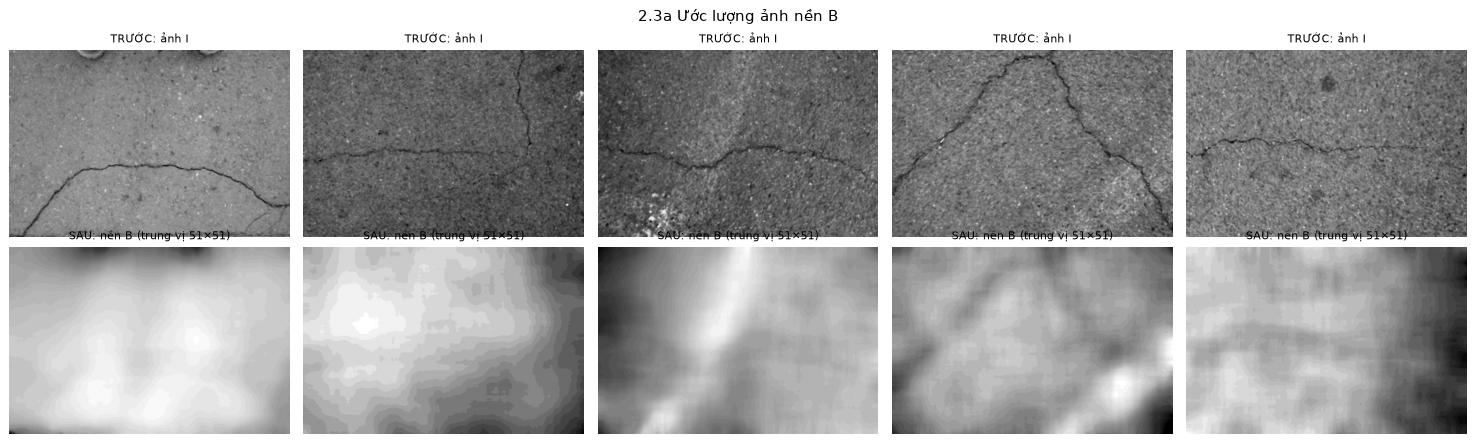

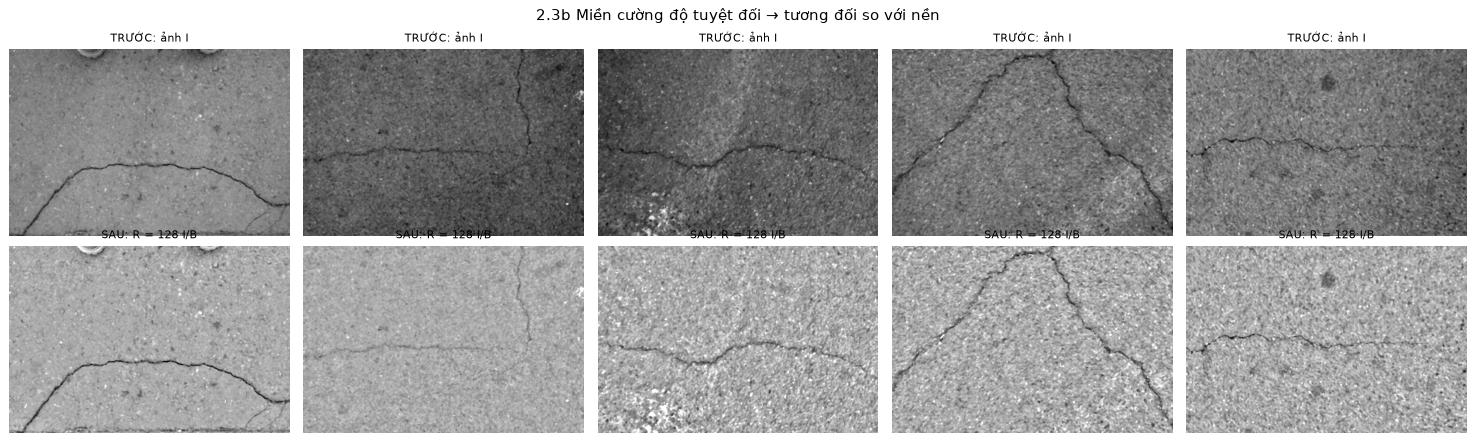

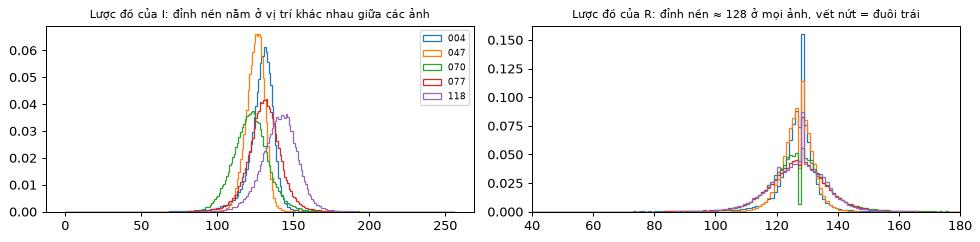

In [8]:
def illumination_ratio(img, bg_ksize):
    bg = cv2.medianBlur(img, bg_ksize)
    ratio = np.clip(128.0 * img.astype(np.float32) / (bg.astype(np.float32) + 1.0), 0, 255).astype(np.uint8)
    return ratio, bg

S_RATIO, S_BG = zip(*[illumination_ratio(m, P0["bg"]) for m in S_MED])
show_before_after(S_MED, S_BG, ["ảnh I"] * 5, [f"nền B (trung vị {P0['bg']}×{P0['bg']})"] * 5, "2.3a Ước lượng ảnh nền B")
show_before_after(S_MED, S_RATIO, ["ảnh I"] * 5, ["R = 128·I/B"] * 5,
                  "2.3b Miền cường độ tuyệt đối → tương đối so với nền", vmin_a=60, vmax_a=160)
fig, ax = plt.subplots(1, 2, figsize=(11, 2.8))
for j in range(5):
    ax[0].hist(S_MED[j].ravel(), 256, range=(0, 256), histtype="step", density=True, label=SAMPLE_IDS[j])
    ax[1].hist(S_RATIO[j].ravel(), 256, range=(0, 256), histtype="step", density=True, label=SAMPLE_IDS[j])
ax[0].set_title("Lược đồ của I: đỉnh nền nằm ở vị trí khác nhau giữa các ảnh")
ax[1].set_title("Lược đồ của R: đỉnh nền ≈ 128 ở mọi ảnh, vết nứt = đuôi trái")
ax[1].set_xlim(40, 180); ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()

---
# Bước 3 – Xử lý chính (Chương 5, 7)

## 3.1 Làm trơn lược đồ của R (Chương 5, tr.62)

| | |
|---|---|
| **Dùng gì** | Làm trơn lược đồ h[b] bằng **trung bình trượt cửa sổ W**: h'[b] = (1/W)·Σ h[b+k], với k từ −W/2 đến W/2. Phép này không làm dịch vị trí đỉnh |
| **Tham số** | Khởi đầu **W = 3**; thử **1 (không làm trơn), 3, 5** trên tập tune |
| **Tại sao** | Giáo trình nêu: các thuật toán tìm ngưỡng tự động thường làm trơn lược đồ để khử dao động nhỏ (W thường là 3 hoặc 5). Với ảnh R, bước này **bắt buộc**. R = 128·I/B được tính từ các số nguyên I, B rồi làm tròn (lượng tử hóa, Ch2), nên một số mức nhận nhiều pixel hơn hẳn mức kế bên. Lược đồ vì vậy có một **gai ở 128 nằm ngay cạnh một hố ở 127**. Không làm trơn thì thuật toán tam giác (3.2) chọn đúng hố 127 làm ngưỡng, và D phủ khoảng **50% ảnh** (xem hình dưới) |

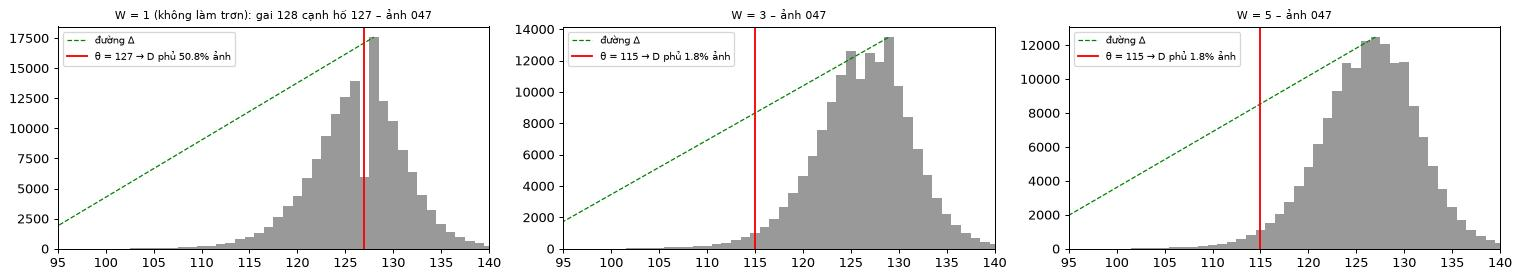

In [9]:
def histogram(img, w=1):
    """Lược đồ xám, làm trơn bằng trung bình trượt cửa sổ w (Ch5 tr.62); w = 1: không làm trơn."""
    h = np.bincount(img.ravel(), minlength=256).astype(np.float64)
    if w > 1:
        h = np.convolve(np.pad(h, w // 2, mode="edge"), np.ones(w) / w, mode="valid")
    return h

def triangle_threshold(img, w=3):
    """3.2 – Zack: Δ nối (b_min, h[b_min]) – (b_max, h[b_max]); θ = b có khoảng cách tới Δ lớn nhất.
    Đuôi đối tượng nằm ở phía TỐI (mức thấp) của đỉnh nền."""
    h = histogram(img, w)
    bmax = int(np.argmax(h)); bmin = int(np.nonzero(h)[0][0])
    if bmax == bmin:
        return bmax
    b = np.arange(bmin, bmax + 1)
    x1, y1, x2, y2 = bmin, h[bmin], bmax, h[bmax]
    d = np.abs((y2 - y1) * b - (x2 - x1) * h[b] + x2 * y1 - y2 * x1) / np.hypot(y2 - y1, x2 - x1)
    return int(b[np.argmax(d)])

# Minh họa: lược đồ R của ảnh tune 047 khi KHÔNG làm trơn và khi làm trơn W = 3, 5
r047 = illumination_ratio(cv2.medianBlur(to_gray(read_pair("047")[0]), 3), P0["bg"])[0]
fig, ax = plt.subplots(1, 3, figsize=(17, 3.2))
for a, w in zip(ax, (1, 3, 5)):
    hh = histogram(r047, w); t = triangle_threshold(r047, w); bmin = int(np.nonzero(hh)[0][0]); bmax = int(np.argmax(hh))
    a.bar(np.arange(256), hh, width=1, color="0.6"); a.plot([bmin, bmax], [hh[bmin], hh[bmax]], "g--", lw=1, label="đường Δ")
    a.axvline(t, color="red", label=f"θ = {t} → D phủ {np.mean(r047 < t)*100:.1f}% ảnh"); a.set_xlim(95, 140); a.legend(fontsize=8)
    a.set_title(f"W = {w}" + (" (không làm trơn): gai 128 cạnh hố 127" if w == 1 else "") + " – ảnh 047")
plt.tight_layout(); plt.show()

## 3.2 Vùng tối hơn nền D: ngưỡng tam giác (Chương 5, tr.78)

| | |
|---|---|
| **Dùng gì** | Thuật toán tam giác của Zack trên lược đồ **đã làm trơn**: (1) nối đỉnh lược đồ (b_max) với mức khác 0 xa nhất về phía đuôi tối (b_min) bằng đường thẳng Δ; (2) với mỗi b nằm giữa b_min và b_max, tính khoảng cách d từ h[b] tới Δ; (3) **θ = b có d lớn nhất**. Gán **D = (R < θ)**. Ảnh xám được chuyển thành **ảnh nhị phân** |
| **Tham số** | Không có. **θ được tính tự động** lại cho từng ảnh |
| **Tại sao tam giác** | Sau bước 2.3, lược đồ R có **một đỉnh rất lớn** (nền, khoảng 98%) và một **đuôi dài mỏng** về phía tối (vết nứt, khoảng 2%). Đây đúng là loại lược đồ mà phương pháp tam giác được thiết kế cho |
| **Tại sao không dùng Otsu** | **Otsu** giả định lược đồ có **hai đỉnh**. Khi một lớp chỉ chiếm 2%, phương sai giữa hai lớp bị lớp nền chi phối, nên Otsu đặt ngưỡng vào giữa đỉnh nền và gán quá nhiều pixel là vết nứt (xem hình dưới) |

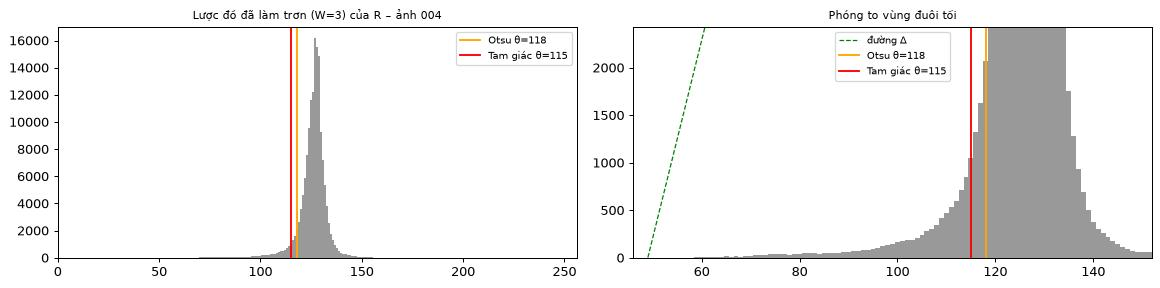

Tỉ lệ pixel bị gán là nứt: Otsu 7.5% | tam giác 4.9% | GT 1.3%


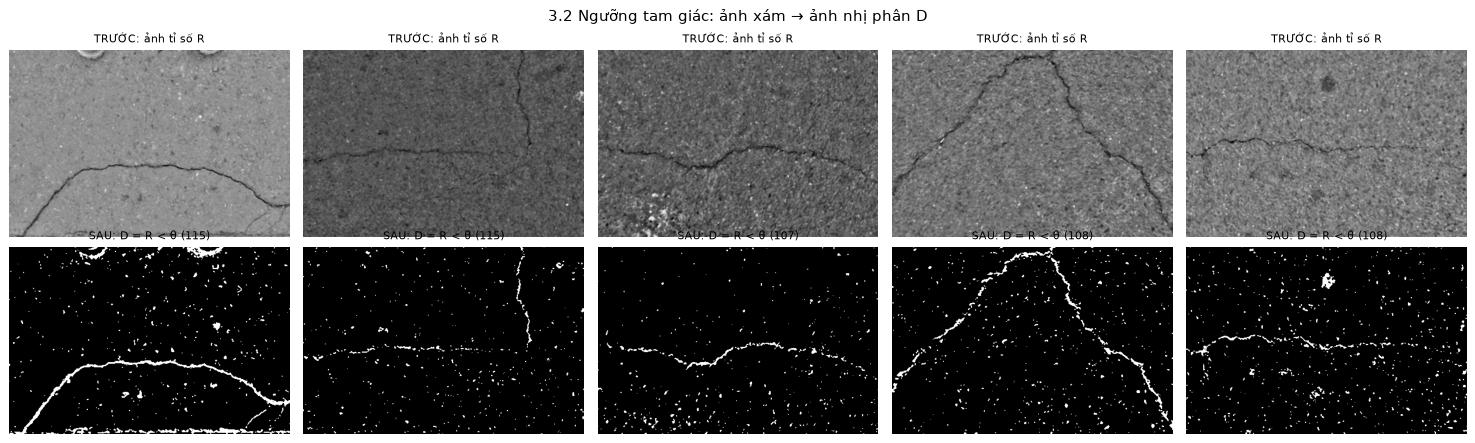

In [10]:
def dark_region(ratio, w=3):
    t = triangle_threshold(ratio, w)
    return ratio < t, t

j = 0; r = S_RATIO[j]
h = histogram(r, P0["hist_w"])
t_tri = triangle_threshold(r, P0["hist_w"]); t_otsu, _ = cv2.threshold(r, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
bmin, bmax = int(np.nonzero(h)[0][0]), int(np.argmax(h))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.3))
for k, lim in enumerate([(0, 256), (bmin - 3, bmax + 25)]):
    ax[k].bar(np.arange(256), h, width=1, color="0.6")
    if k == 1: ax[k].plot([bmin, bmax], [h[bmin], h[bmax]], "g--", lw=1, label="đường Δ")
    ax[k].axvline(t_otsu, color="orange", lw=1.5, label=f"Otsu θ={t_otsu:.0f}")
    ax[k].axvline(t_tri, color="red", lw=1.5, label=f"Tam giác θ={t_tri}")
    ax[k].set_xlim(*lim); ax[k].legend(fontsize=8)
ax[0].set_title(f"Lược đồ đã làm trơn (W=3) của R – ảnh {SAMPLE_IDS[j]}"); ax[1].set_title("Phóng to vùng đuôi tối"); ax[1].set_ylim(0, h[bmax] * 0.15)
plt.tight_layout(); plt.show()
print(f"Tỉ lệ pixel bị gán là nứt: Otsu {np.mean(r < t_otsu)*100:.1f}% | tam giác {np.mean(r < t_tri)*100:.1f}% | GT {S_GT[j].mean()*100:.1f}%")

S_D, S_T = zip(*[dark_region(r, P0["hist_w"]) for r in S_RATIO])
show_before_after(S_RATIO, [u8(m) for m in S_D], ["ảnh tỉ số R"] * 5, [f"D = R < θ ({t})" for t in S_T],
                  "3.2 Ngưỡng tam giác: ảnh xám → ảnh nhị phân D")

## 3.3 Vùng gần biên mạnh E: Sobel + Otsu + giãn (Chương 5, 7)

| | |
|---|---|
| **Dùng gì** | (1) Sobel 3×3 trên R, lấy **\|∇R\| = \|Gx\| + \|Gy\|** (xấp xỉ chuẩn L1 của gradient), rồi chuẩn hóa về [0, 255]. (2) Tách ngưỡng **Otsu** trên \|∇R\| để lấy **biên mạnh**. (3) **Giãn** mặt nạ biên bằng phần tử cấu trúc **ellipse** để được E |
| **Tham số** | Khởi đầu: giãn **ellipse 5×5**; thử **3, 5, 7** trên tập tune |
| **Tại sao dùng biên** | Vết nứt thật vừa **tối** vừa có **biên sắc** (chuyển đột ngột từ nền sang khe nứt). Một số vùng tối nhưng chuyển sáng tối **từ từ** (vệt bóng còn sót, vết ẩm loang) sẽ vượt qua bước 3.2 nhưng **không có biên mạnh**. Vì vậy E dùng để loại các vùng này |
| **Tại sao dùng \|Gx\| + \|Gy\|** | Đây là xấp xỉ quen thuộc của độ lớn gradient trong Ch5: không cần căn bậc hai, và có thứ tự lớn nhỏ gần giống √(Gx² + Gy²) |
| **Tại sao dùng Otsu ở đây** | Khác với lược đồ R (một đỉnh), lược đồ của \|∇R\| gồm **hai nhóm rõ ràng hơn** (vùng phẳng và vùng biên), nên giả định hai lớp của Otsu hợp lý hơn |
| **Tại sao phải giãn** | Ngay **tại tâm** một vết nứt mảnh, gradient **bằng 0**; biên chỉ nằm ở **hai bờ**. Phải giãn ra mới phủ được thân vết nứt. Ellipse đẳng hướng nên vết nứt theo hướng nào cũng được xử lý như nhau. Giãn ít (3×3) thì E chặt và loại được nhiều vùng hơn; giãn nhiều (7×7) thì E gần như phủ hết D |

```
R:   128 128 128  80 128 128 128
Gx:    0   0 -192   0 192   0   0     → |∇R|: 0 0 192 0 192 0 0   (tâm nứt = 0!)
Otsu:  · · █ · █ · ·     giãn ─►  E:  · █ █ █ █ █ ·   (phủ kín thân vết nứt)
```

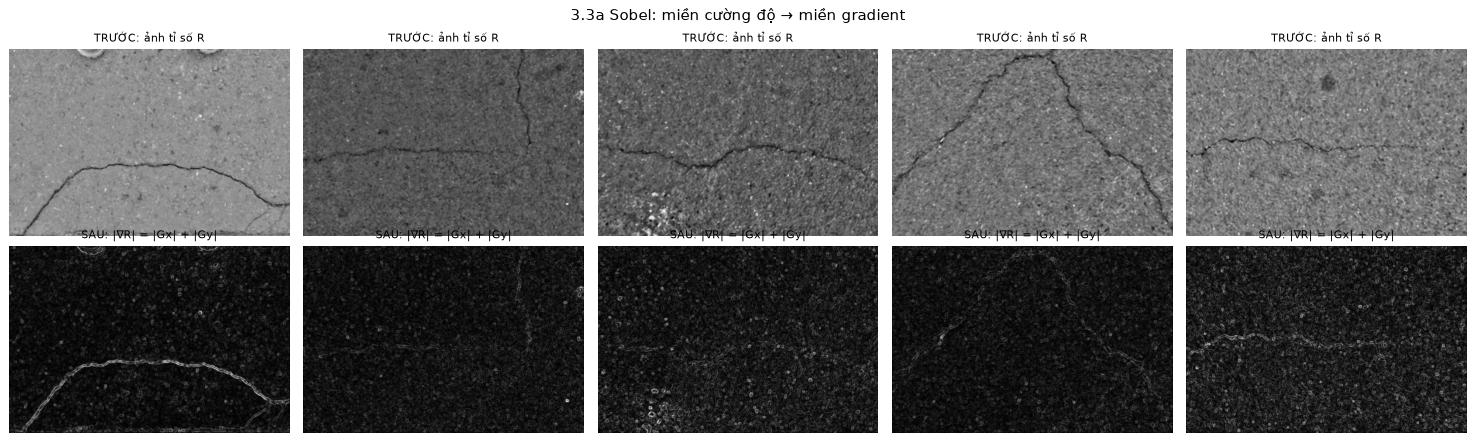

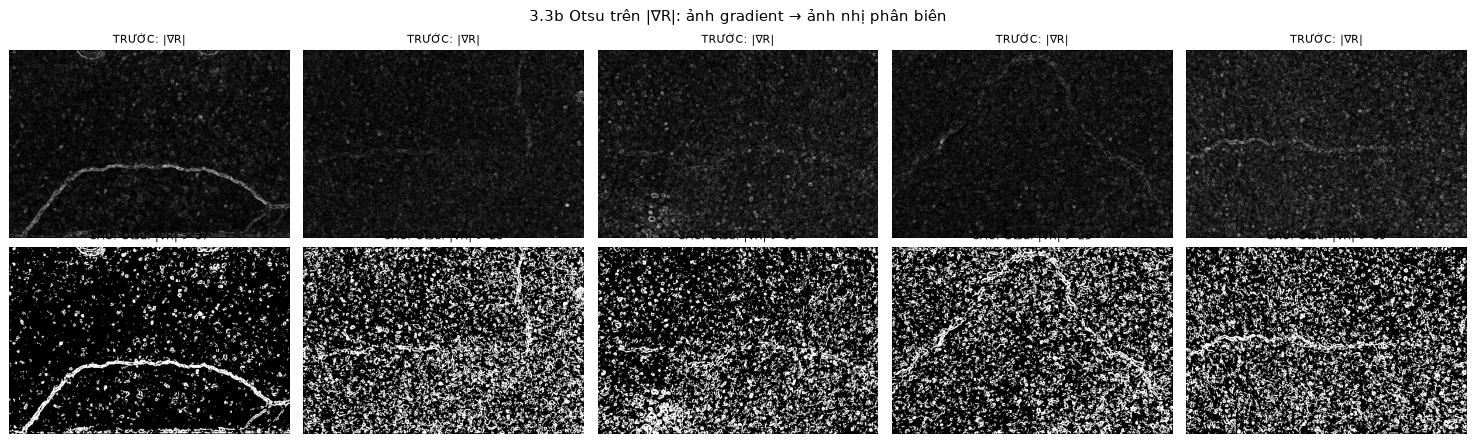

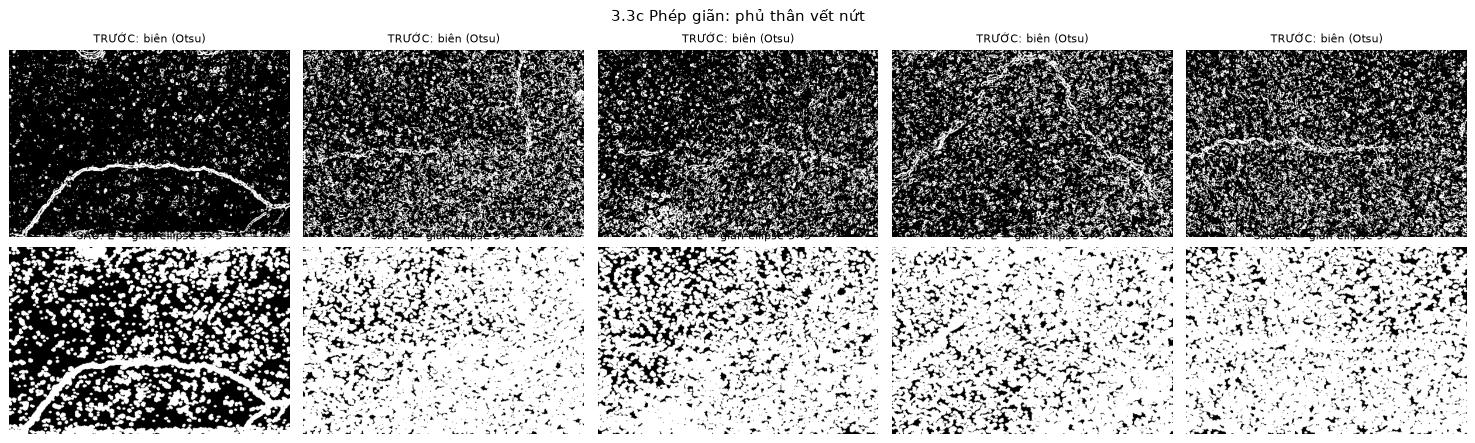

In [11]:
def sobel_l1(img):
    gx = cv2.Sobel(img, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(img, cv2.CV_32F, 0, 1, ksize=3)
    return cv2.normalize(np.abs(gx) + np.abs(gy), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

def ellipse(k):
    return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))

def edge_region(ratio, dil):
    g = sobel_l1(ratio)
    t, edge = cv2.threshold(g, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return cv2.dilate(edge, ellipse(dil)) > 0, g, edge > 0, t

S_E, S_G, S_EDGE, S_TE = zip(*[edge_region(r, P0["dil"]) for r in S_RATIO])
show_before_after(S_RATIO, S_G, ["ảnh tỉ số R"] * 5, ["|∇R| = |Gx| + |Gy|"] * 5,
                  "3.3a Sobel: miền cường độ → miền gradient")
show_before_after(S_G, [u8(e) for e in S_EDGE], ["|∇R|"] * 5, [f"Otsu: |∇R| > {t:.0f}" for t in S_TE],
                  "3.3b Otsu trên |∇R|: ảnh gradient → ảnh nhị phân biên")
show_before_after([u8(e) for e in S_EDGE], [u8(e) for e in S_E], ["biên (Otsu)"] * 5, [f"E = giãn ellipse {P0['dil']}×{P0['dil']}"] * 5,
                  "3.3c Phép giãn: phủ thân vết nứt")

## 3.4 Mặt nạ thô M = D ∩ E

| | |
|---|---|
| **Dùng gì** | Giao hai mặt nạ nhị phân: một pixel là vết nứt khi nó **vừa tối hơn nền** (D) **vừa nằm gần biên mạnh** (E) |
| **Tham số** | Không có |
| **Tại sao** | D bắt được hầu hết vết nứt nhưng lẫn các mảng tối loang. E bắt mọi biên, kể cả biên của hạt sỏi sáng. **Giao** của chúng giữ những gì thỏa **cả hai** điều kiện. M luôn là **tập con của D**: bước này chỉ xóa bớt pixel, không bao giờ thêm |

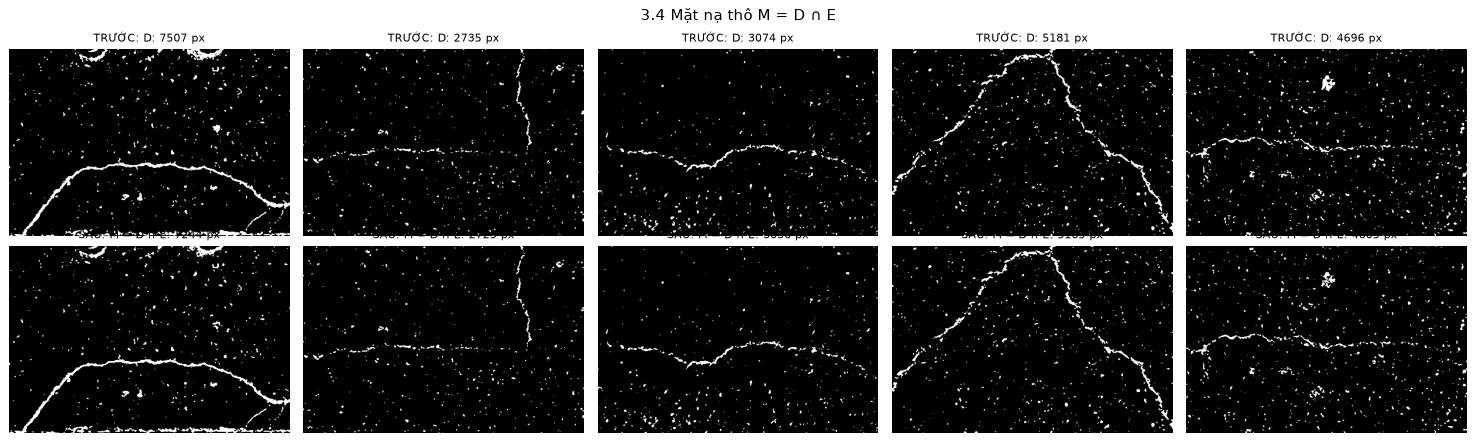

In [12]:
S_M = [d & e for d, e in zip(S_D, S_E)]
show_before_after([u8(d) for d in S_D], [u8(m) for m in S_M],
                  [f"D: {d.sum()} px" for d in S_D], [f"M = D ∩ E: {m.sum()} px" for m in S_M],
                  "3.4 Mặt nạ thô M = D ∩ E")

---
# Bước 4 – Hậu xử lý (Chương 7)

## 4.1 Phép đóng

| | |
|---|---|
| **Dùng gì** | Phép đóng **A • B = (A ⊕ B) ⊖ B** (giãn rồi co) với B là ellipse |
| **Tham số** | Khởi đầu **ellipse 5×5**; thử **3, 5, 7** trên tập tune |
| **Tại sao** | Vết nứt thật có những chỗ **hẹp hoặc sáng hơn**, nên sau bước 3 nó bị **đứt thành nhiều đoạn**. Phép đóng lấp các khe nhỏ hơn B và **nối** các đoạn lại. Nhờ phép co ở bước sau, vết nứt **không bị dày lên vĩnh viễn** như khi chỉ giãn. Việc nối đoạn còn giúp bước 4.2 không xóa nhầm các đoạn nứt ngắn. B quá lớn (7×7) có thể dính các vệt nhiễu gần nhau vào vết nứt |

```
Trước (2 vùng):                        Sau phép đóng 5×5 (1 vùng):
·███████···········                    ·███████···········
·███████·█████████·         ──►        ·█████████████████·
·········█████████·                    ·········█████████·
```

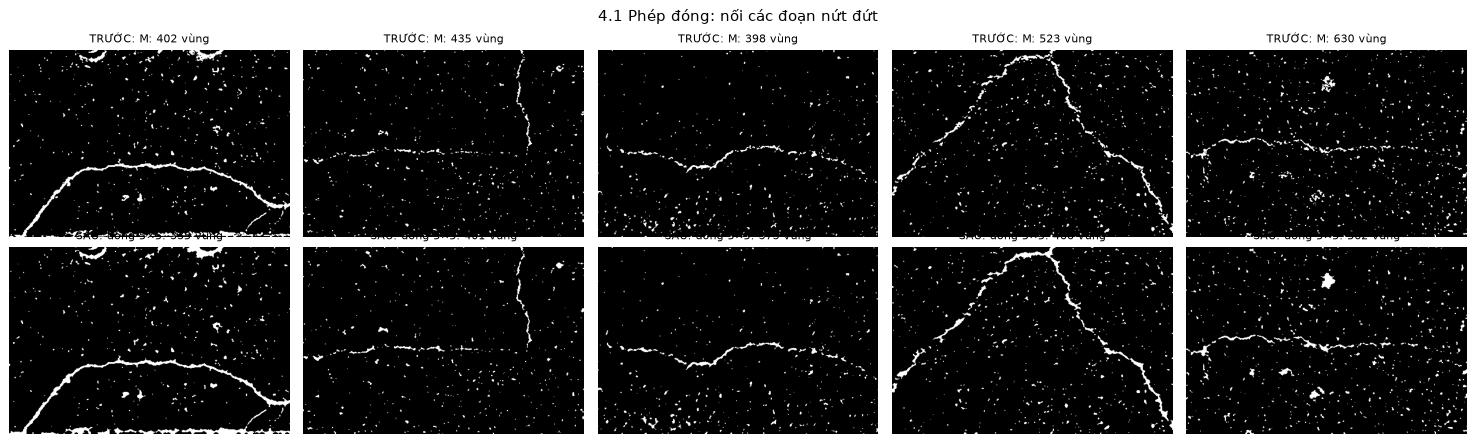

In [13]:
def closing(mask, k):
    return cv2.morphologyEx(mask.astype(np.uint8), cv2.MORPH_CLOSE, ellipse(k)) > 0

S_C = [closing(m, P0["close"]) for m in S_M]
show_before_after([u8(m) for m in S_M], [u8(m) for m in S_C],
                  [f"M: {ncc(m)} vùng" for m in S_M], [f"đóng {P0['close']}×{P0['close']}: {ncc(m)} vùng" for m in S_C],
                  "4.1 Phép đóng: nối các đoạn nứt đứt")

## 4.2 Lọc vùng theo diện tích

| | |
|---|---|
| **Dùng gì** | Gán nhãn **thành phần liên thông** theo **8-láng giềng** (`cv2.connectedComponentsWithStats`), rồi **bỏ** các vùng có diện tích **< a_min** |
| **Tham số** | Khởi đầu **a_min = 30 px**; thử **15, 30, 60** trên tập tune |
| **Tại sao** | Sau phép đóng vẫn còn các **đốm nhỏ** do hạt sỏi tối hoặc lỗ nhỏ. Các đốm này rời rạc và có diện tích nhỏ, còn vết nứt là các vùng **liên thông dài và lớn**. Với 30 px, một vết nứt rộng 2 px chỉ cần dài khoảng 15 px là được giữ. Thử 15 (giữ được đoạn nứt ngắn) và 60 (loại nhiễu mạnh hơn). Dùng **8-láng giềng** để các pixel nối chéo của vết nứt xiên vẫn được tính là một vùng |

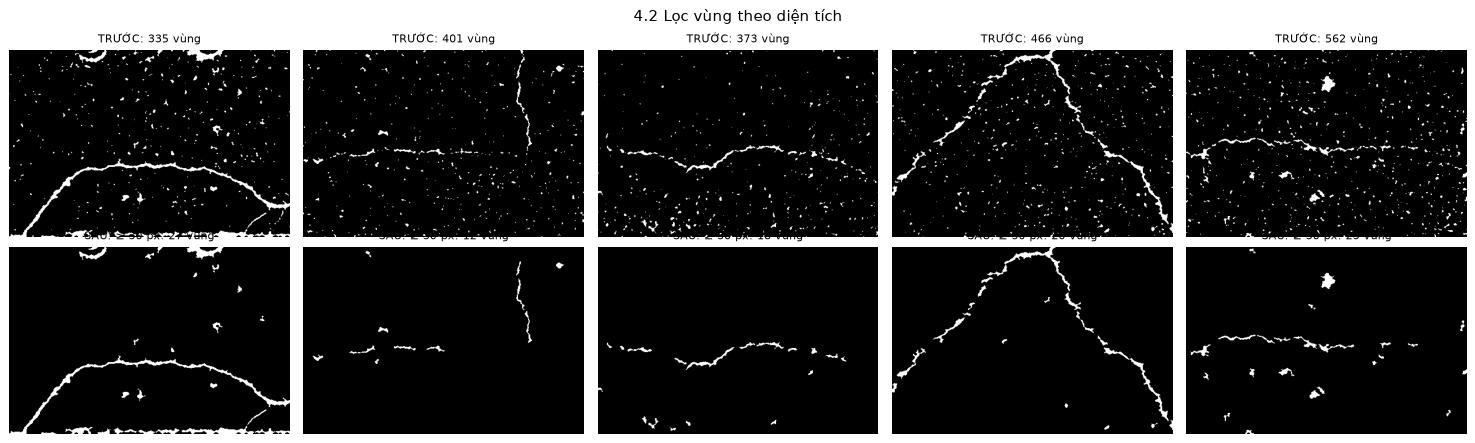

In [14]:
def area_filter(mask, a_min):
    n, lab, st, _ = cv2.connectedComponentsWithStats(mask.astype(np.uint8), connectivity=8)
    keep = st[:, cv2.CC_STAT_AREA] >= a_min
    keep[0] = False
    return keep[lab]

S_A = [area_filter(m, P0["a_min"]) for m in S_C]
show_before_after([u8(m) for m in S_C], [u8(m) for m in S_A],
                  [f"{ncc(m)} vùng" for m in S_C], [f"≥ {P0['a_min']} px: {ncc(m)} vùng" for m in S_A],
                  "4.2 Lọc vùng theo diện tích")

## 4.3 Lọc theo độ dãn: trục dài / trục ngắn của hộp chữ nhật xoay

| | |
|---|---|
| **Dùng gì** | Với mỗi vùng, tìm **hộp chữ nhật xoay có diện tích nhỏ nhất** bao vùng đó (`cv2.minAreaRect`). Hộp có cạnh dài L và cạnh ngắn S. **Độ dãn = L / S**, với S được lấy tối thiểu 1 px để nét 1 px không bị chia cho 0. Bỏ vùng có **độ dãn < e_min** |
| **Tham số** | Khởi đầu **e_min = 3**; thử **2, 3, 4** trên tập tune |
| **Tại sao** | Vết nứt **dài và mảnh** nên hộp bao rất dẹt (L ≫ S). Ngược lại, vết dầu, ổ gà nhỏ, đốm tối lớn có diện tích đủ lớn để qua bước 4.2 nhưng **gần tròn hoặc vuông** (L/S ≈ 1). Ngưỡng 3 nghĩa là vùng phải dài **ít nhất gấp 3 lần** bề rộng |
| **Tại sao dùng hộp xoay** | Hộp **xoay** theo hướng của vùng nên đo đúng tỉ lệ dài/rộng của cả vết nứt **chéo**. Hộp thẳng đứng (không xoay) bao một vết nứt chéo 45° sẽ gần vuông, nên vết nứt bị xóa nhầm |
| **Hạn chế** | Vết nứt **cong** hoặc **phân nhánh** có hộp bao "phình" ra, nên độ dãn thấp hơn thực tế. Vì vậy thử cả e_min = 2 (lỏng hơn) |

,hình,diện tích,L/S hộp xoay,L/S hộp thẳng,giữ (e_min = 3)?
0,đốm tròn r = 5,81,1.00,1.00,False
1,đốm vuông 9×9,81,1.00,1.00,False
2,"vết nứt ngang dày 2, dài 40",125,21.00,14.33,True
3,vết nứt chéo 45° dày 2,207,20.50,1.00,True
4,vết nứt cong (cung tròn),173,2.75,2.65,False


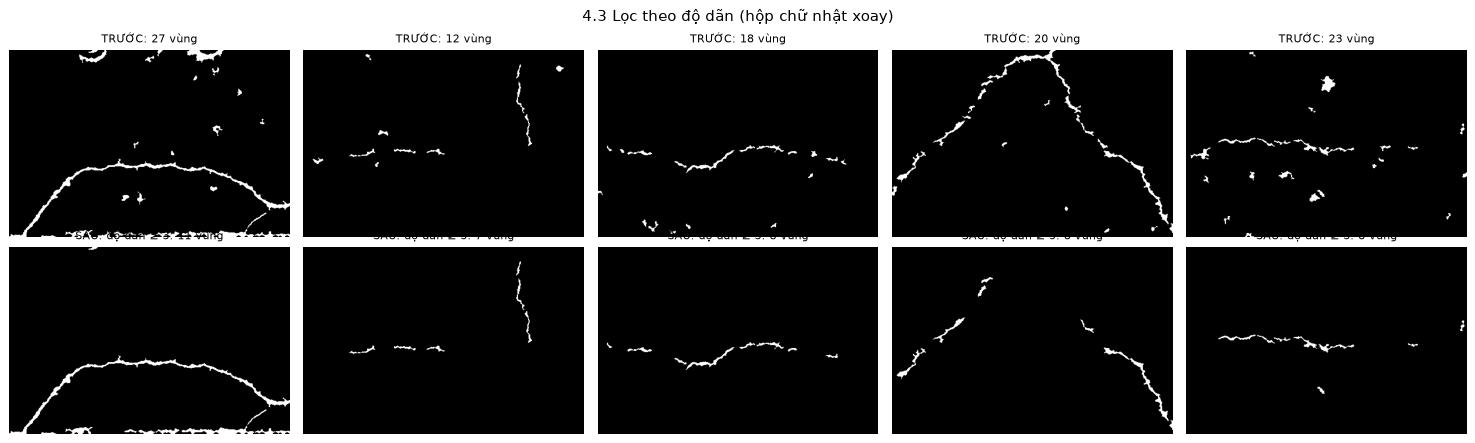

Các vùng của ảnh 047 trước bước 4.3:


,vùng,diện tích,độ dãn L/S,giữ
0,1,40,2.43,False
1,2,63,6.19,True
2,3,83,1.08,False
3,4,158,4.88,True
4,5,151,7.39,True
5,6,85,1.97,False
6,7,91,4.21,True
7,8,111,6.71,True
8,9,98,3.38,True
9,10,32,3.36,True


In [15]:
def elongation(comp):
    """Trục dài / trục ngắn của hộp chữ nhật xoay nhỏ nhất bao vùng."""
    (_, _), (w, h), _ = cv2.minAreaRect(cv2.findNonZero(comp.astype(np.uint8)))
    return max(w, h) / max(min(w, h), 1.0)

def elongation_filter(mask, e_min, return_table=False):
    n, lab, st, _ = cv2.connectedComponentsWithStats(mask.astype(np.uint8), connectivity=8)
    keep = np.zeros(n, bool); rows = []
    for i in range(1, n):
        x, y, w, h = st[i, :4]
        e = elongation(lab[y:y + h, x:x + w] == i)
        keep[i] = e >= e_min
        rows.append({"vùng": i, "diện tích": st[i, cv2.CC_STAT_AREA], "độ dãn L/S": round(e, 2), "giữ": keep[i]})
    return (keep[lab], pd.DataFrame(rows)) if return_table else keep[lab]

# Ví dụ trên hình tổng hợp: hộp xoay đo đúng vết nứt chéo, còn hộp thẳng thì không
demo = []
for name, draw in [("đốm tròn r = 5", lambda m: cv2.circle(m, (30, 30), 5, 1, -1)),
                   ("đốm vuông 9×9", lambda m: cv2.rectangle(m, (26, 26), (34, 34), 1, -1)),
                   ("vết nứt ngang dày 2, dài 40", lambda m: cv2.line(m, (10, 30), (50, 30), 1, 2)),
                   ("vết nứt chéo 45° dày 2", lambda m: cv2.line(m, (10, 10), (50, 50), 1, 2)),
                   ("vết nứt cong (cung tròn)", lambda m: cv2.ellipse(m, (30, 45), (22, 22), 0, 200, 340, 1, 2))]:
    m = np.zeros((60, 60), np.uint8); draw(m)
    x, y, w, h = cv2.boundingRect(m)
    demo.append({"hình": name, "diện tích": int(m.sum()), "L/S hộp xoay": round(elongation(m > 0), 2),
                 "L/S hộp thẳng": round(max(w, h) / min(w, h), 2), "giữ (e_min = 3)?": elongation(m > 0) >= 3})
display(pd.DataFrame(demo))

S_F = [elongation_filter(m, P0["e_min"]) for m in S_A]
show_before_after([u8(m) for m in S_A], [u8(m) for m in S_F],
                  [f"{ncc(m)} vùng" for m in S_A], [f"độ dãn ≥ {P0['e_min']}: {ncc(m)} vùng" for m in S_F],
                  "4.3 Lọc theo độ dãn (hộp chữ nhật xoay)")
_, tab = elongation_filter(S_A[1], P0["e_min"], return_table=True)
print(f"Các vùng của ảnh {SAMPLE_IDS[1]} trước bước 4.3:")
tab

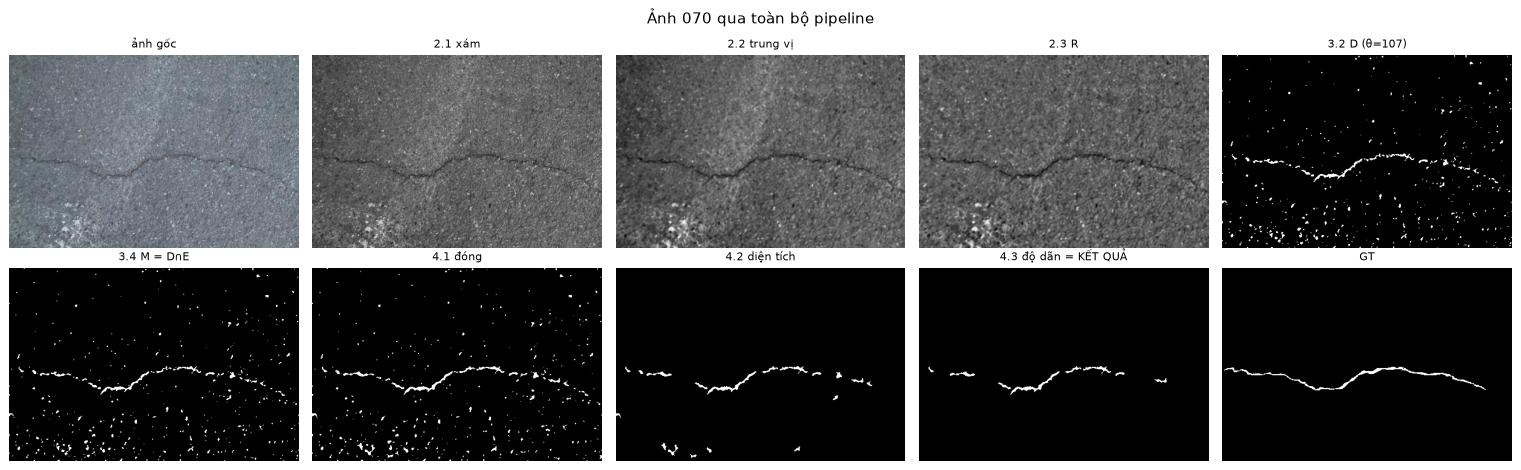

In [16]:
# Toàn bộ pipeline (bước 2 → 4)
def raw_mask(img, p):
    """Bước 2 + 3: ảnh gốc -> mặt nạ thô M (và các ảnh trung gian)."""
    gray = to_gray(img)
    den = cv2.medianBlur(gray, p["median"])
    ratio = illumination_ratio(den, p["bg"])[0] if p.get("bg", 0) > 1 else den   # bg = 0: thí nghiệm không bù sáng
    D, theta = dark_region(ratio, p["hist_w"])
    M = D & edge_region(ratio, p["dil"])[0] if p.get("use_edge", True) else D
    return M, dict(gray=gray, den=den, ratio=ratio, D=D, theta=theta)

def post(M, p):
    """Bước 4: phép đóng -> lọc diện tích -> lọc độ dãn."""
    C = closing(M, p["close"])
    A = area_filter(C, p["a_min"])
    return elongation_filter(A, p["e_min"]), C, A

def pipeline(img, p, steps=False):
    M, st = raw_mask(img, p)
    if not p.get("post", True):
        return M
    F, C, A = post(M, p)
    return dict(st, M=M, C=C, A=A, F=F) if steps else F

# Một ảnh qua mọi bước (tham số khởi đầu)
st = pipeline(S_IMG[2], P0, steps=True)
seq = [("ảnh gốc", rgb(S_IMG[2])), ("2.1 xám", st["gray"]), ("2.2 trung vị", st["den"]), ("2.3 R", st["ratio"]),
       (f"3.2 D (θ={st['theta']})", st["D"]), ("3.4 M = D∩E", st["M"]), ("4.1 đóng", st["C"]), ("4.2 diện tích", st["A"]),
       ("4.3 độ dãn = KẾT QUẢ", st["F"]), ("GT", S_GT[2])]
fig, ax = plt.subplots(2, 5, figsize=(17, 5.4))
for a, (t, im) in zip(ax.ravel(), seq):
    a.imshow(im, cmap=None if im.ndim == 3 else "gray"); a.set_title(t); a.axis("off")
plt.suptitle(f"Ảnh {SAMPLE_IDS[2]} qua toàn bộ pipeline", fontsize=12); plt.tight_layout(); plt.show()

---
# Chọn tham số trên tập tune (30 ảnh)

* **Lưới thử** (cột "Dãy thử" của bảng pipeline):

  | Tham số | Bước | Dãy thử |
  |---|---|---|
  | `median` | 2.2 | 3, 5 |
  | `bg` | 2.3 | 31, 51, 71 |
  | `hist_w` | 3.1 | 1, 3, 5 |
  | `dil` | 3.3 | 3, 5, 7 |
  | `close` | 4.1 | 3, 5, 7 |
  | `a_min` | 4.2 | 15, 30, 60 |
  | `e_min` | 4.3 | 2, 3, 4 |

  Tổng cộng 2 × 3 × 3 × 3 × 3 × 3 × 3 = **1458 cấu hình**, thử **toàn bộ** (không bỏ tổ hợp nào).
* **Tiêu chí chọn:** **Dice trung bình theo ảnh** trên tập tune. **Tập test không được dùng** ở bước này.
* **Tăng tốc:** mặt nạ thô M chỉ phụ thuộc 4 tham số của bước 2–3 (2 × 3 × 3 × 3 = 54 tổ hợp), nên được tính một lần cho mỗi tổ hợp rồi tái sử dụng cho 27 tổ hợp hậu xử lý. Kết quả **giống hệt** chạy lại toàn bộ.

In [17]:
def scores(pred, gt):
    tp = int(np.count_nonzero(pred & gt)); fp = int(np.count_nonzero(pred & ~gt)); fn = int(np.count_nonzero(~pred & gt))
    tn = gt.size - tp - fp - fn
    return dict(tp=tp, fp=fp, fn=fn, tn=tn,
                dice=2 * tp / (2 * tp + fp + fn) if tp + fp + fn else 1.0,
                iou=tp / (tp + fp + fn) if tp + fp + fn else 1.0,
                precision=tp / (tp + fp) if tp + fp else 0.0,
                recall=tp / (tp + fn) if tp + fn else 0.0)

PRE_KEYS, POST_KEYS = ["median", "bg", "hist_w", "dil"], ["close", "a_min", "e_min"]
TUNE = [read_pair(i) for i in TUNE_IDS]
rows = []
t0 = time.time()
for pre in itertools.product(*(TUNE_SPACE[k] for k in PRE_KEYS)):
    pp = dict(zip(PRE_KEYS, pre))
    Ms = [raw_mask(img, {**P0, **pp})[0] for img, _ in TUNE]                      # bước 2–3: tính 1 lần
    for postv in itertools.product(*(TUNE_SPACE[k] for k in POST_KEYS)):
        p = {**P0, **pp, **dict(zip(POST_KEYS, postv))}
        s = pd.DataFrame([scores(post(M, p)[0], gt) for M, (_, gt) in zip(Ms, TUNE)])
        rows.append({**{k: p[k] for k in PRE_KEYS + POST_KEYS}, "dice": s.dice.mean(), "iou": s.iou.mean(),
                     "precision": s.precision.mean(), "recall": s.recall.mean(), "ảnh hỏng (Dice<0.1)": int((s.dice < 0.1).sum())})
TUNE_LOG = pd.DataFrame(rows)
TUNE_LOG["khởi đầu"] = np.all([TUNE_LOG[k] == P0[k] for k in PRE_KEYS + POST_KEYS], axis=0)
TUNE_LOG = TUNE_LOG.sort_values("dice", ascending=False).reset_index(drop=True)
TUNE_LOG.to_csv(os.path.join(RES, "tune_log.csv"), index=False)
best = TUNE_LOG.iloc[0]
P = {k: int(best[k]) for k in PRE_KEYS + POST_KEYS}
json.dump(P, open(os.path.join(RES, "best_params.json"), "w"), indent=1)
start = TUNE_LOG[TUNE_LOG["khởi đầu"]].iloc[0]
print(f"{len(TUNE_LOG)} cấu hình, {time.time()-t0:.0f}s")
print(f"Tham số khởi đầu: {P0}  → Dice tune {start.dice:.3f}, IoU {start.iou:.3f} (hạng {TUNE_LOG.index[TUNE_LOG['khởi đầu']][0]+1})")
print(f"Tham số chọn    : {P}  → Dice tune {best.dice:.3f}, IoU {best.iou:.3f}")
TUNE_LOG.head(15)

1458 cấu hình, 88s
Tham số khởi đầu: {'median': 3, 'bg': 51, 'hist_w': 3, 'dil': 5, 'close': 5, 'a_min': 30, 'e_min': 3}  → Dice tune 0.502, IoU 0.351 (hạng 64)
Tham số chọn    : {'median': 3, 'bg': 31, 'hist_w': 3, 'dil': 7, 'close': 7, 'a_min': 60, 'e_min': 2}  → Dice tune 0.523, IoU 0.367


,median,bg,hist_w,dil,close,a_min,e_min,dice,iou,precision,recall,ảnh hỏng (Dice<0.1),khởi đầu
0,3,31,3,7,7,60,2,0.523,0.367,0.549,0.550,0,False
1,3,31,3,5,7,60,2,0.523,0.367,0.550,0.549,0,False
2,3,31,3,3,7,60,2,0.519,0.363,0.552,0.536,0,False
3,3,51,3,5,7,60,2,0.519,0.364,0.527,0.568,0,False
4,3,51,3,7,7,60,2,0.518,0.363,0.525,0.570,0,False
5,3,51,3,3,7,60,2,0.518,0.363,0.532,0.561,0,False
6,3,51,5,5,7,60,2,0.516,0.363,0.554,0.540,1,False
7,3,51,5,7,7,60,2,0.515,0.363,0.553,0.541,1,False
8,3,71,3,3,5,30,2,0.515,0.362,0.540,0.544,0,False
9,3,71,5,5,7,60,2,0.514,0.362,0.529,0.563,0,False


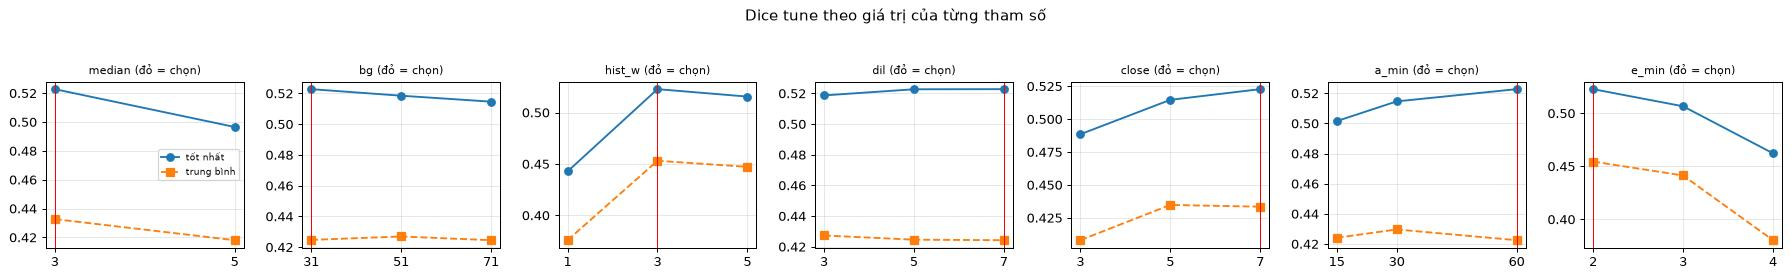

,1,2,3,4,5,7,15,30,31,51,60,71
tham số,,,,,,,,,,,,
median,,,0.523,,0.497,,,,,,,
bg,,,,,,,,,0.523,0.519,,0.515
hist_w,0.443,,0.523,,0.516,,,,,,,
dil,,,0.519,,0.523,0.523,,,,,,
close,,,0.489,,0.515,0.523,,,,,,
a_min,,,,,,,0.502,0.515,,,0.523,
e_min,,0.523,0.507,0.462,,,,,,,,


In [18]:
# Ảnh hưởng của từng tham số: Dice tune TỐT NHẤT (giữ các tham số khác tối ưu) và TRUNG BÌNH theo từng giá trị
keys = PRE_KEYS + POST_KEYS
fig, ax = plt.subplots(1, len(keys), figsize=(20, 2.9))
eff = {}
for a, k in zip(ax, keys):
    g = TUNE_LOG.groupby(k).dice
    a.plot(g.max().index, g.max().values, "o-", label="tốt nhất"); a.plot(g.mean().index, g.mean().values, "s--", label="trung bình")
    a.axvline(P[k], color="red", lw=0.8); a.set_title(f"{k} (đỏ = chọn)"); a.set_xticks(list(g.max().index)); a.grid(alpha=.3)
    eff[k] = g.max().round(3).to_dict()
ax[0].legend(fontsize=7); plt.suptitle("Dice tune theo giá trị của từng tham số", y=1.05); plt.tight_layout(); plt.show()
pd.DataFrame({k: pd.Series(v) for k, v in eff.items()}).T.rename_axis("tham số").fillna("")

### Phân tích kết quả chọn tham số

| Bước | Tham số | Khởi đầu | **Chọn** | Dice tune tốt nhất theo từng giá trị thử | Nhận xét |
|---|---|---|---|---|---|
| 2.2 | trung vị | 3×3 | **3×3** | 3: **0.523**, 5: 0.497 | 5×5 xóa luôn nét nứt rộng 2 px |
| 2.3 | cửa sổ nền | 51 | **31** | 31: **0.523**, 51: 0.519, 71: 0.515 | Ít nhạy (chênh ≤ 0.008). Cửa sổ nhỏ theo kịp bóng đổ cục bộ tốt hơn |
| 3.1 | làm trơn W | 3 | **3** | 1: 0.443, 3: **0.523**, 5: 0.516 | Không làm trơn là lỗi nặng nhất (xem 3.1). W = 5 làm tù đuôi tối nên θ hơi lệch |
| 3.3 | giãn biên | 5×5 | **7×7** | 3: 0.519, 5: **0.523**, 7: **0.523** | Giãn càng lớn thì E càng phủ hết D, nên 3.3 gần như không còn tác dụng (xem bước 5) |
| 4.1 | phép đóng | 5×5 | **7×7** | 3: 0.489, 5: 0.515, 7: **0.523** | Nối đoạn đứt quan trọng: 3×3 thấp hơn 0.034 |
| 4.2 | diện tích tối thiểu | 30 | **60** | 15: 0.502, 30: 0.515, 60: **0.523** | Sau phép đóng 7×7, vết nứt đã liền thành vùng lớn nên lọc mạnh hơn được |
| 4.3 | độ dãn tối thiểu | 3 | **2** | 2: **0.523**, 3: 0.507, 4: 0.462 | Vết nứt CFD thường **cong và phân nhánh**, nên hộp xoay "phình" ra và độ dãn thấp. Ngưỡng 3–4 xóa nhầm vết nứt thật (ví dụ cung tròn trong bảng ở 4.3 chỉ có L/S = 2.75) |

**Nhận xét chung.**
* Tham số khởi đầu đã khá tốt: Dice tune 0.502, xếp hạng 64/1458. Tham số chọn đạt **0.523** (+0.021).
* Hai thay đổi đóng góp nhiều nhất là **e_min 3 → 2** (vết nứt cong) và **phép đóng 5 → 7** cùng **a_min 30 → 60**. Hai thay đổi sau đi theo cặp: đóng mạnh hơn làm vết nứt liền thành vùng lớn, nên có thể lọc diện tích mạnh hơn mà không mất vết nứt.
* Bốn giá trị được chọn nằm ở **biên của dãy thử**: bg = 31 (nhỏ nhất), close = 7, a_min = 60 (lớn nhất), e_min = 2 (nhỏ nhất). Có thể còn cấu hình tốt hơn ngoài dãy thử. Tuy vậy, chênh lệch giữa các cấu hình trong top 15 chỉ khoảng 0.01, nên lợi ích còn lại nhiều khả năng nhỏ.

---
# Bước 5 – Đánh giá trên tập test (88 ảnh)

### Độ đo
Các độ đo tính trên **từng pixel** của mỗi ảnh, so với GT nhị phân:

$$\text{Dice} = \frac{2TP}{2TP+FP+FN},\quad \text{IoU} = \frac{TP}{TP+FP+FN},\quad \text{Precision} = \frac{TP}{TP+FP},\quad \text{Recall} = \frac{TP}{TP+FN}$$

* Dice chính là **F1 mức pixel**. IoU = Dice / (2 − Dice), nên IoU luôn ≤ Dice.
* Báo cáo **trung bình theo ảnh ± độ lệch chuẩn** và **độ đo gộp** (cộng dồn TP, FP, FN của 88 ảnh rồi mới tính).

### Đối chứng
* **Otsu:** ảnh xám, ngưỡng Otsu toàn cục, pixel tối hơn ngưỡng là vết nứt. Đây là cách tách ngưỡng tự động cơ bản nhất của Ch5.
* **Canny:** ảnh xám, `cv2.Canny(50, 150)`, pixel biên là vết nứt. Đây là bộ dò biên chuẩn của Ch5.

### Thí nghiệm bổ sung (bỏ một bước để thấy đóng góp của nó)
Các thí nghiệm này dùng **cùng tham số đã chọn** cho pipeline:
* Bỏ 2.3 (không bù chiếu sáng)
* Bỏ 3.1 (W = 1, không làm trơn lược đồ)
* Bỏ 3.3 (M = D, không dùng biên)
* Bỏ bước 4 (không hậu xử lý)

In [19]:
def baseline_otsu(img):
    _, m = cv2.threshold(to_gray(img), 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    return m > 0

def baseline_canny(img):
    return cv2.Canny(to_gray(img), 50, 150) > 0

MAIN = "Pipeline (tham số đã chọn)"
METHODS = {
    "Đối chứng: Otsu": baseline_otsu,
    "Đối chứng: Canny": baseline_canny,
    "Pipeline (tham số khởi đầu)": lambda im: pipeline(im, P0),
    MAIN: lambda im: pipeline(im, P),
    "Bỏ 2.3 (không bù sáng)": lambda im: pipeline(im, {**P, "bg": 0}),
    "Bỏ 3.1 (W = 1)": lambda im: pipeline(im, {**P, "hist_w": 1}),
    "Bỏ 3.3 (M = D)": lambda im: pipeline(im, {**P, "use_edge": False}),
    "Bỏ bước 4 (không hậu xử lý)": lambda im: pipeline(im, {**P, "post": False}),
}
rows = []
for sid in TEST_IDS:
    img, gt = read_pair(sid)
    for name, f in METHODS.items():
        rows.append({"id": sid, "phương pháp": name, **scores(f(img), gt)})
PER_IMAGE = pd.DataFrame(rows); PER_IMAGE.to_csv(os.path.join(RES, "test_per_image.csv"), index=False)

g = PER_IMAGE.groupby("phương pháp", sort=False); s = g[["tp", "fp", "fn", "tn"]].sum()
SUMMARY = pd.DataFrame({
    "số ảnh": g.size(),
    "Dice": g.dice.mean(), "± std Dice": g.dice.std(),
    "IoU": g.iou.mean(), "± std IoU": g.iou.std(),
    "Precision": g.precision.mean(), "Recall": g.recall.mean(),
    "Dice gộp": 2 * s.tp / (2 * s.tp + s.fp + s.fn), "IoU gộp": s.tp / (s.tp + s.fp + s.fn),
    "ảnh hỏng (Dice<0.1)": g.dice.apply(lambda d: int((d < 0.1).sum())),
})
SUMMARY.to_csv(os.path.join(RES, "test_summary.csv"))
SUMMARY

,số ảnh,Dice,± std Dice,IoU,± std IoU,Precision,Recall,Dice gộp,IoU gộp,ảnh hỏng (Dice<0.1)
phương pháp,,,,,,,,,,
Đối chứng: Otsu,88,0.061,0.045,0.032,0.025,0.032,0.852,0.059,0.030,79
Đối chứng: Canny,88,0.060,0.066,0.032,0.042,0.040,0.393,0.049,0.025,77
Pipeline (tham số khởi đầu),88,0.532,0.190,0.383,0.164,0.606,0.538,0.550,0.379,3
Pipeline (tham số đã chọn),88,0.538,0.180,0.387,0.154,0.561,0.578,0.564,0.392,3
Bỏ 2.3 (không bù sáng),88,0.417,0.208,0.285,0.163,0.457,0.436,0.452,0.292,8
Bỏ 3.1 (W = 1),88,0.476,0.227,0.338,0.177,0.450,0.576,0.529,0.359,11
Bỏ 3.3 (M = D),88,0.536,0.179,0.385,0.153,0.558,0.578,0.562,0.391,3
Bỏ bước 4 (không hậu xử lý),88,0.385,0.135,0.247,0.103,0.309,0.573,0.404,0.253,2


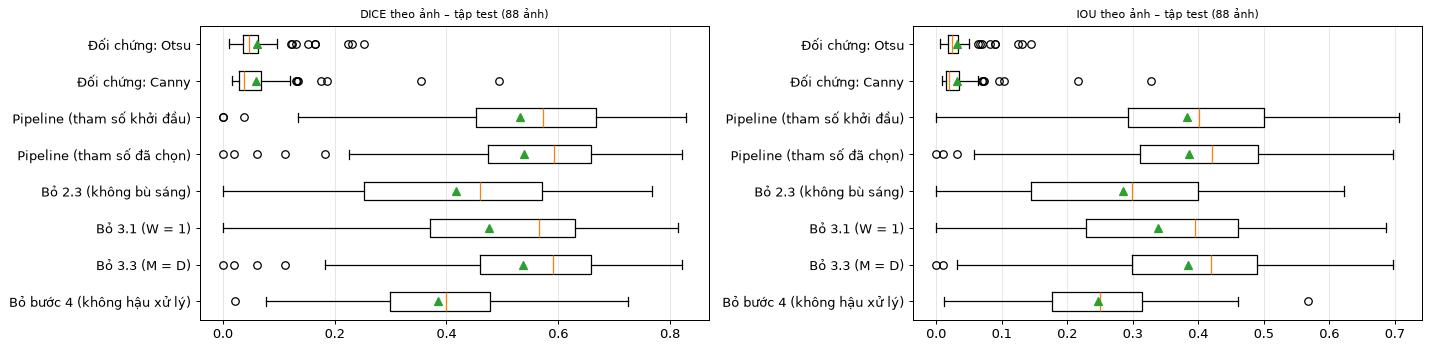

Tỉ lệ ảnh test mà pipeline (tham số đã chọn) có Dice CAO HƠN: {'Bỏ 2.3 (không bù sáng)': '90%', 'Bỏ 3.1 (W = 1)': '69%', 'Bỏ 3.3 (M = D)': '10%', 'Bỏ bước 4 (không hậu xử lý)': '90%', 'Pipeline (tham số khởi đầu)': '40%', 'Đối chứng: Canny': '98%', 'Đối chứng: Otsu': '98%'}
Tỉ lệ ảnh có Dice BẰNG NHAU: {'Bỏ 2.3 (không bù sáng)': '1%', 'Bỏ 3.1 (W = 1)': '7%', 'Bỏ 3.3 (M = D)': '89%', 'Bỏ bước 4 (không hậu xử lý)': '0%', 'Pipeline (tham số khởi đầu)': '1%', 'Đối chứng: Canny': '0%', 'Đối chứng: Otsu': '0%'}


In [20]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4))
names = list(METHODS)
for a, k in zip(ax, ["dice", "iou"]):
    a.boxplot([PER_IMAGE[PER_IMAGE["phương pháp"] == n][k] for n in names], orientation="horizontal", tick_labels=names, showmeans=True)
    a.set_title(f"{k.upper()} theo ảnh – tập test (88 ảnh)"); a.invert_yaxis(); a.grid(alpha=.3, axis="x")
plt.tight_layout(); plt.show()
pv = PER_IMAGE.pivot(index="id", columns="phương pháp", values="dice")
print("Tỉ lệ ảnh test mà pipeline (tham số đã chọn) có Dice CAO HƠN:",
      {c: f"{(pv[MAIN] > pv[c]).mean()*100:.0f}%" for c in pv if c != MAIN})
print("Tỉ lệ ảnh có Dice BẰNG NHAU:", {c: f"{(pv[MAIN] == pv[c]).mean()*100:.0f}%" for c in pv if c != MAIN})

### Trực quan hóa: phủ mặt nạ đỏ lên ảnh gốc (tập test)
Các hàng lần lượt là: ảnh gốc, GT, Otsu, Canny, pipeline, và **bản đồ lỗi** của pipeline. Trên bản đồ lỗi: **xanh lá** = đúng (TP), **đỏ** = báo nhầm (FP), **xanh dương** = bỏ sót (FN).

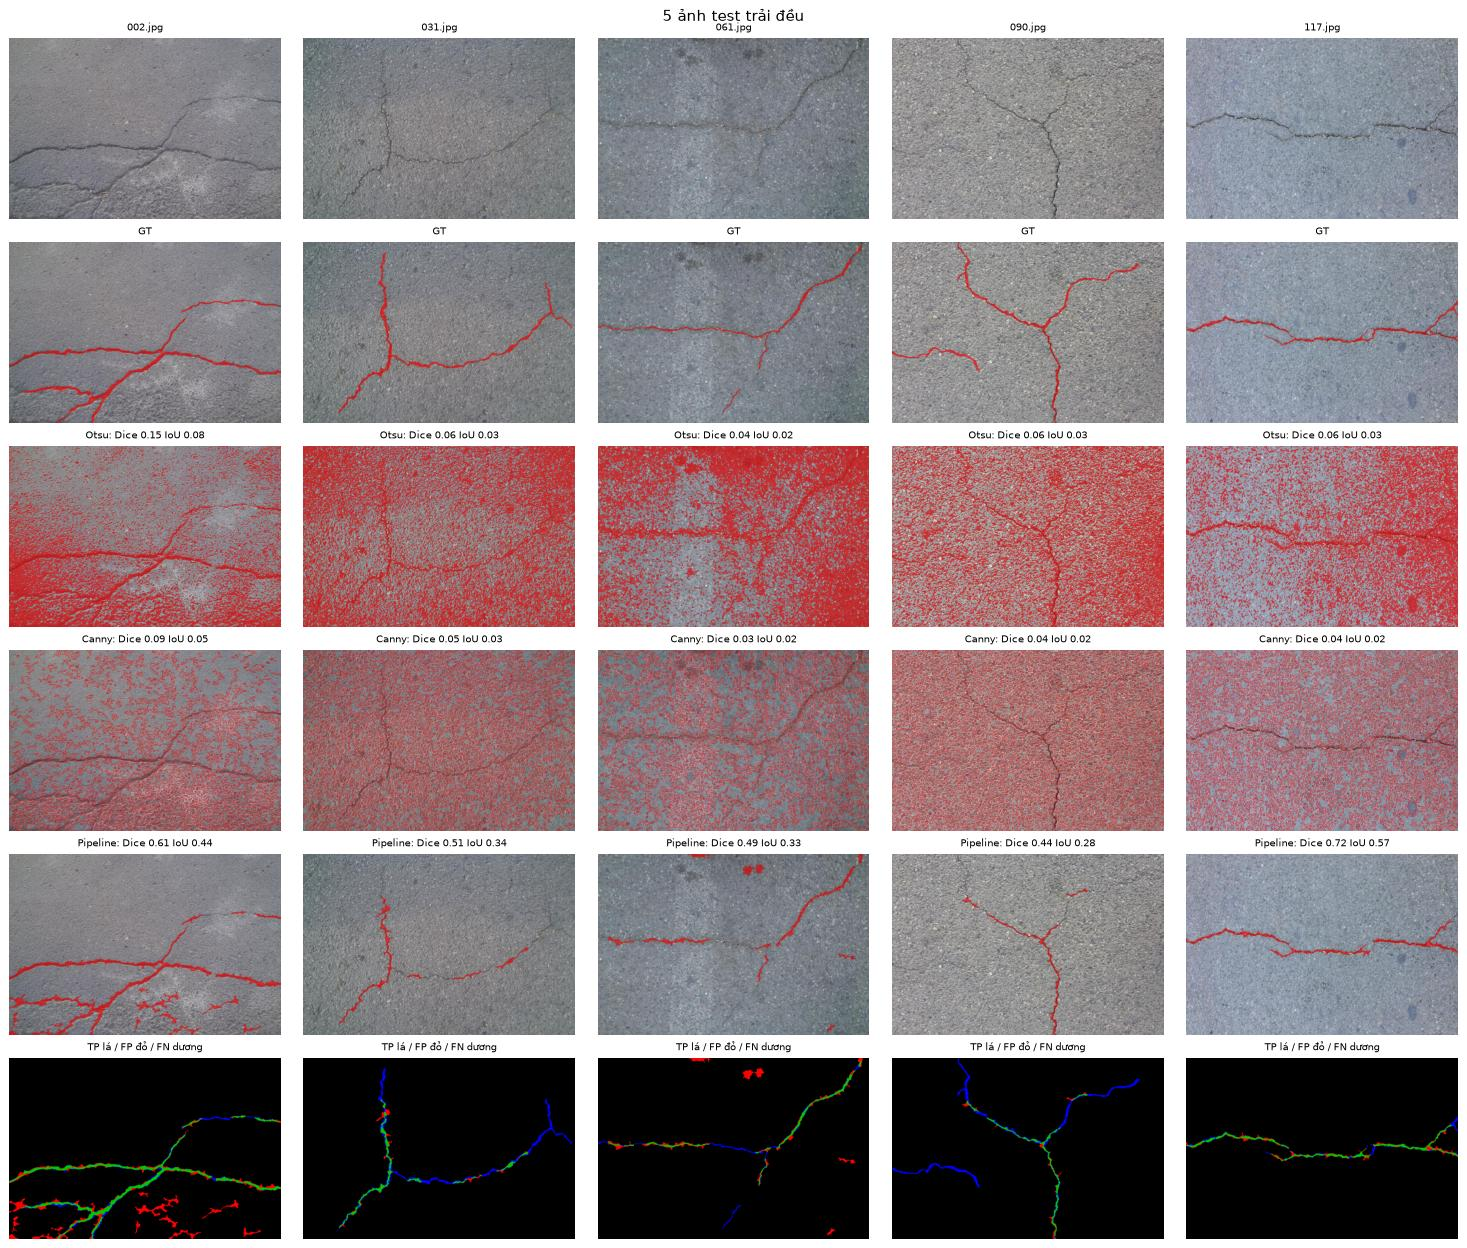

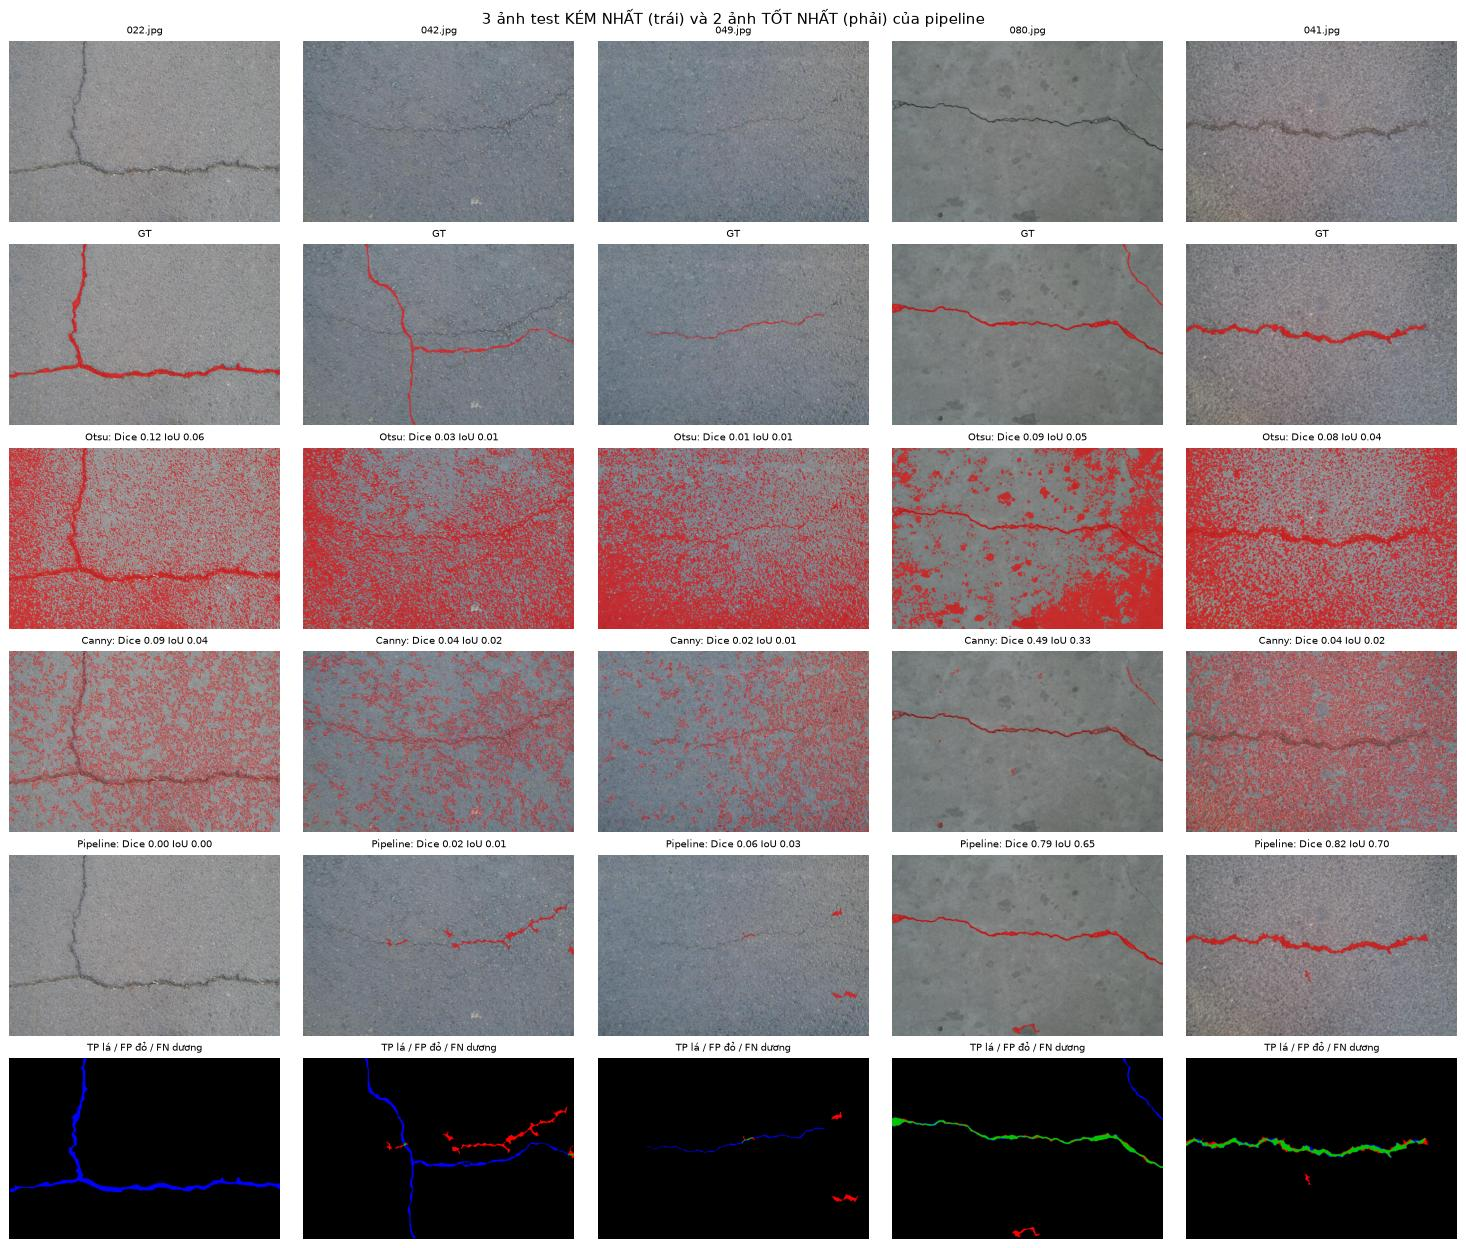

In [21]:
def show_test(ids, title):
    rows_ = [("Ảnh gốc", None), ("GT", None), ("Otsu", "Đối chứng: Otsu"), ("Canny", "Đối chứng: Canny"), ("Pipeline", MAIN), ("Bản đồ lỗi", MAIN)]
    fig, ax = plt.subplots(len(rows_), len(ids), figsize=(3.3 * len(ids), 2.35 * len(rows_)))
    for j, sid in enumerate(ids):
        img, gt = read_pair(sid)
        for i, (lab, name) in enumerate(rows_):
            if lab == "Ảnh gốc":
                vis, t = img, f"{sid}.jpg"
            elif lab == "GT":
                vis, t = overlay_red(img, gt), "GT"
            else:
                pr = METHODS[name](img); sc = scores(pr, gt)
                vis = error_map(pr, gt) if lab == "Bản đồ lỗi" else overlay_red(img, pr)
                t = "TP lá / FP đỏ / FN dương" if lab == "Bản đồ lỗi" else f"{lab}: Dice {sc['dice']:.2f} IoU {sc['iou']:.2f}"
            ax[i, j].imshow(rgb(vis)); ax[i, j].set_title(t, fontsize=8); ax[i, j].axis("off")
    fig.suptitle(title, fontsize=12); plt.tight_layout(); plt.show()

show_test([TEST_IDS[k] for k in np.linspace(0, 87, 5).astype(int)], "5 ảnh test trải đều")
d = PER_IMAGE[PER_IMAGE["phương pháp"] == MAIN].sort_values("dice")
show_test(list(d.id.head(3)) + list(d.id.tail(2)), "3 ảnh test KÉM NHẤT (trái) và 2 ảnh TỐT NHẤT (phải) của pipeline")

In [22]:
# Lưu 10 ảnh test mẫu (ảnh + GT + kết quả phủ đỏ) vào samples/
SAMPLE_DIR = os.path.join(ROOT, "samples")
os.makedirs(SAMPLE_DIR, exist_ok=True)
for f in os.listdir(SAMPLE_DIR):
    os.remove(os.path.join(SAMPLE_DIR, f))
for sid in [TEST_IDS[k] for k in np.linspace(0, 87, 10).astype(int)]:
    img, gt = read_pair(sid)
    cv2.imwrite(os.path.join(SAMPLE_DIR, f"{sid}.jpg"), img)
    cv2.imwrite(os.path.join(SAMPLE_DIR, f"{sid}_gt.png"), u8(gt))
    cv2.imwrite(os.path.join(SAMPLE_DIR, f"{sid}_pred.jpg"), overlay_red(img, pipeline(img, P)))
print(sorted(os.listdir(SAMPLE_DIR)))

['002.jpg', '002_gt.png', '002_pred.jpg', '013.jpg', '013_gt.png', '013_pred.jpg', '027.jpg', '027_gt.png', '027_pred.jpg', '041.jpg', '041_gt.png', '041_pred.jpg', '054.jpg', '054_gt.png', '054_pred.jpg', '066.jpg', '066_gt.png', '066_pred.jpg', '081.jpg', '081_gt.png', '081_pred.jpg', '094.jpg', '094_gt.png', '094_pred.jpg', '105.jpg', '105_gt.png', '105_pred.jpg', '117.jpg', '117_gt.png', '117_pred.jpg']


---
# Thảo luận và kết luận

### Kết quả trên tập test (88 ảnh, trung bình theo ảnh)

| Phương pháp | Dice | IoU | Precision | Recall | Ảnh hỏng (Dice < 0.1) |
|---|---|---|---|---|---|
| Đối chứng: Otsu | 0.061 | 0.032 | 0.032 | 0.852 | 79 / 88 |
| Đối chứng: Canny | 0.060 | 0.032 | 0.040 | 0.393 | 77 / 88 |
| Pipeline – tham số khởi đầu | 0.532 | 0.383 | 0.606 | 0.538 | 3 / 88 |
| **Pipeline – tham số đã chọn** | **0.538** | **0.387** | 0.561 | 0.578 | 3 / 88 |

1. **So với đối chứng:** Dice tăng **khoảng 9 lần** (0.06 → 0.54), và pipeline tốt hơn Otsu và Canny trên **98%** số ảnh test.
   * **Otsu** có recall 0.85 nhưng precision chỉ 0.03: nó gán khoảng một nửa ảnh là vết nứt, vì lược đồ lệch lớp không có hai đỉnh.
   * **Canny** bắt biên của **mọi hạt sỏi**, và chỉ cho đường biên ở hai bờ chứ không cho thân vết nứt.
2. **Kết quả tune và test khớp nhau:** Dice tune 0.523, Dice test 0.538, nên **không có dấu hiệu khớp quá mức**. Chọn tham số trên tập tune giúp tăng Dice test thêm 0.006 so với tham số khởi đầu. Đổi lại, precision giảm và recall tăng, vì phép đóng lớn hơn và ngưỡng độ dãn lỏng hơn giữ lại nhiều vết nứt hơn.
3. **Đóng góp của từng bước** (bỏ một bước, giữ nguyên các tham số khác, so với Dice 0.538):

   | Thay đổi | Dice | Mức giảm | Ảnh hỏng |
   |---|---|---|---|
   | Bỏ bước 4 (không hậu xử lý) | 0.385 | **−0.153** | 2 |
   | Bỏ 2.3 (không bù chiếu sáng) | 0.417 | **−0.121** | 8 |
   | Bỏ 3.1 (W = 1, không làm trơn lược đồ) | 0.476 | **−0.062** | 11 |
   | Bỏ 3.3 (M = D, không dùng biên) | 0.536 | −0.002 | 3 |

   * **Hậu xử lý** và **bù chiếu sáng** là hai bước quan trọng nhất.
   * **Làm trơn lược đồ** không làm tăng Dice trung bình nhiều, nhưng ngăn được **11 ảnh hỏng hoàn toàn** do lỗi lượng tử hóa.
   * **Bước 3.3 (Sobel) gần như không có tác dụng:** 89% ảnh test cho kết quả giống hệt khi bỏ bước này. Lý do: Otsu trên \|∇R\| lấy cả biên của kết cấu sỏi. Đo trên tập test: sau khi giãn 7×7, E phủ trung bình **88.9% ảnh** và chỉ loại **0.9% số pixel của D**. Với giãn 5×5 thì E phủ 77.9% ảnh và loại 1.4% pixel; với giãn 3×3 thì E phủ 52.5% ảnh và loại 6.0% pixel, nhưng Dice tune lại thấp hơn khoảng 0.004. Tức là sau khi đã bù chiếu sáng, "tối hơn nền" và "gần biên" gần như trùng nhau trên CFD. Bước này vẫn được giữ đúng theo bảng pipeline, và nên nêu rõ trong báo cáo rằng đóng góp của nó không đáng kể.

### Phân tích lỗi (xem bản đồ lỗi và các ảnh kém nhất)
* **FN (bỏ sót):** đoạn nứt **mờ hoặc rất hẹp** có độ tối gần với nền, nên không vượt được θ. Ngoài ra còn các mảnh nứt ngắn bị bước 4.2 lọc mất.
* **FP (báo nhầm):** vệt tối dài nhưng **không phải vết nứt** (mép vạch sơn, vệt dầu, khe giữa các viên sỏi lớn), và phần vết nứt bị phép đóng 7×7 làm **dày hơn** GT.
* **GT của CFD rất mảnh (1–3 px):** dự đoán lệch 1 px so với đường tâm cũng bị tính là FP + FN. Vì vậy ngay cả ảnh tốt nhất cũng chỉ đạt Dice 0.82, và chỉ 12/88 ảnh test vượt 0.7.

### Hạn chế
* Ngưỡng θ là **toàn cục trong mỗi ảnh**. Ảnh có nhiều loại mặt đường khác nhau trong cùng khung hình cần ngưỡng cục bộ.
* Lọc độ dãn bằng hộp xoay **đánh giá thấp** vết nứt cong và phân nhánh.
* CFD **ảnh nào cũng có vết nứt**, nên chưa đo được tỉ lệ báo nhầm trên mặt đường lành.

### Tổng kết kiến thức theo chương
| Chương | Kiến thức | Bước |
|---|---|---|
| C3 | Lọc trung vị (khử nhiễu và ước lượng nền), biến đổi điểm (ảnh tỉ số) | 2.2, 2.3 |
| C4 | Hệ màu RGB → ảnh xám | 2.1 |
| C5 | Làm trơn lược đồ, ngưỡng tam giác, gradient Sobel, Otsu, Canny (đối chứng), ma trận nhầm lẫn và các độ đo | 3.1–3.3, 5 |
| C7 | Phép giãn, phép đóng, thành phần liên thông, đặc trưng hình dạng (độ dãn) | 3.3, 4.1–4.3 |
| C9 | Dữ liệu: nguồn, gán nhãn, chia tập có seed, tránh rò rỉ tune/test | 1 |